#실습5_**이미지의 기하학적 변환**

##01 이미지의 어파인 변환 (Affine Transformation)

**어파인 변환(Affine Transformation)**
- 영상을 평행 이동시키거나 회전, 크기 변환 등을 할 수 있음
- 변환 전 이미지와 변환 후 이미지의 세 점의 이동 관계에 의해 결정
- **Affine Transformation Matrix**: 어파인 변환은 두 이미지의 관계를 정의한 2×3 매트릭스로 설명할 수 있음
- 매트릭스는 numpy.float32 실수형 자료형을 사용
  - **uint8**: $2^{8}$개의 0에서 255까지 부호없는 8비트 정수표현
    - 그레이스케일 또는 RGB채널 컬러 이미지를 표현할 때 사용  
  - **float32**: $2^{32}$bits:  부호(1비트)+정수(8비트)+소수(23비트)
    ![Img](https://upload.wikimedia.org/wikipedia/commons/d/d2/Float_example.svg)

**01.1 이동변환(Translation Transformation)**


```
cv2.warpAffine(srcImage,matrix,(width,height))
```

<br>
이동변환의 Affine Matrix:

$$
\mathbf{M}
=
\begin{bmatrix}
    1   &0    &T_x \\
    0   &1   &T_y  \\
\end{bmatrix}
$$





In [ ]:
#구글 드라이브 마운트 하기
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


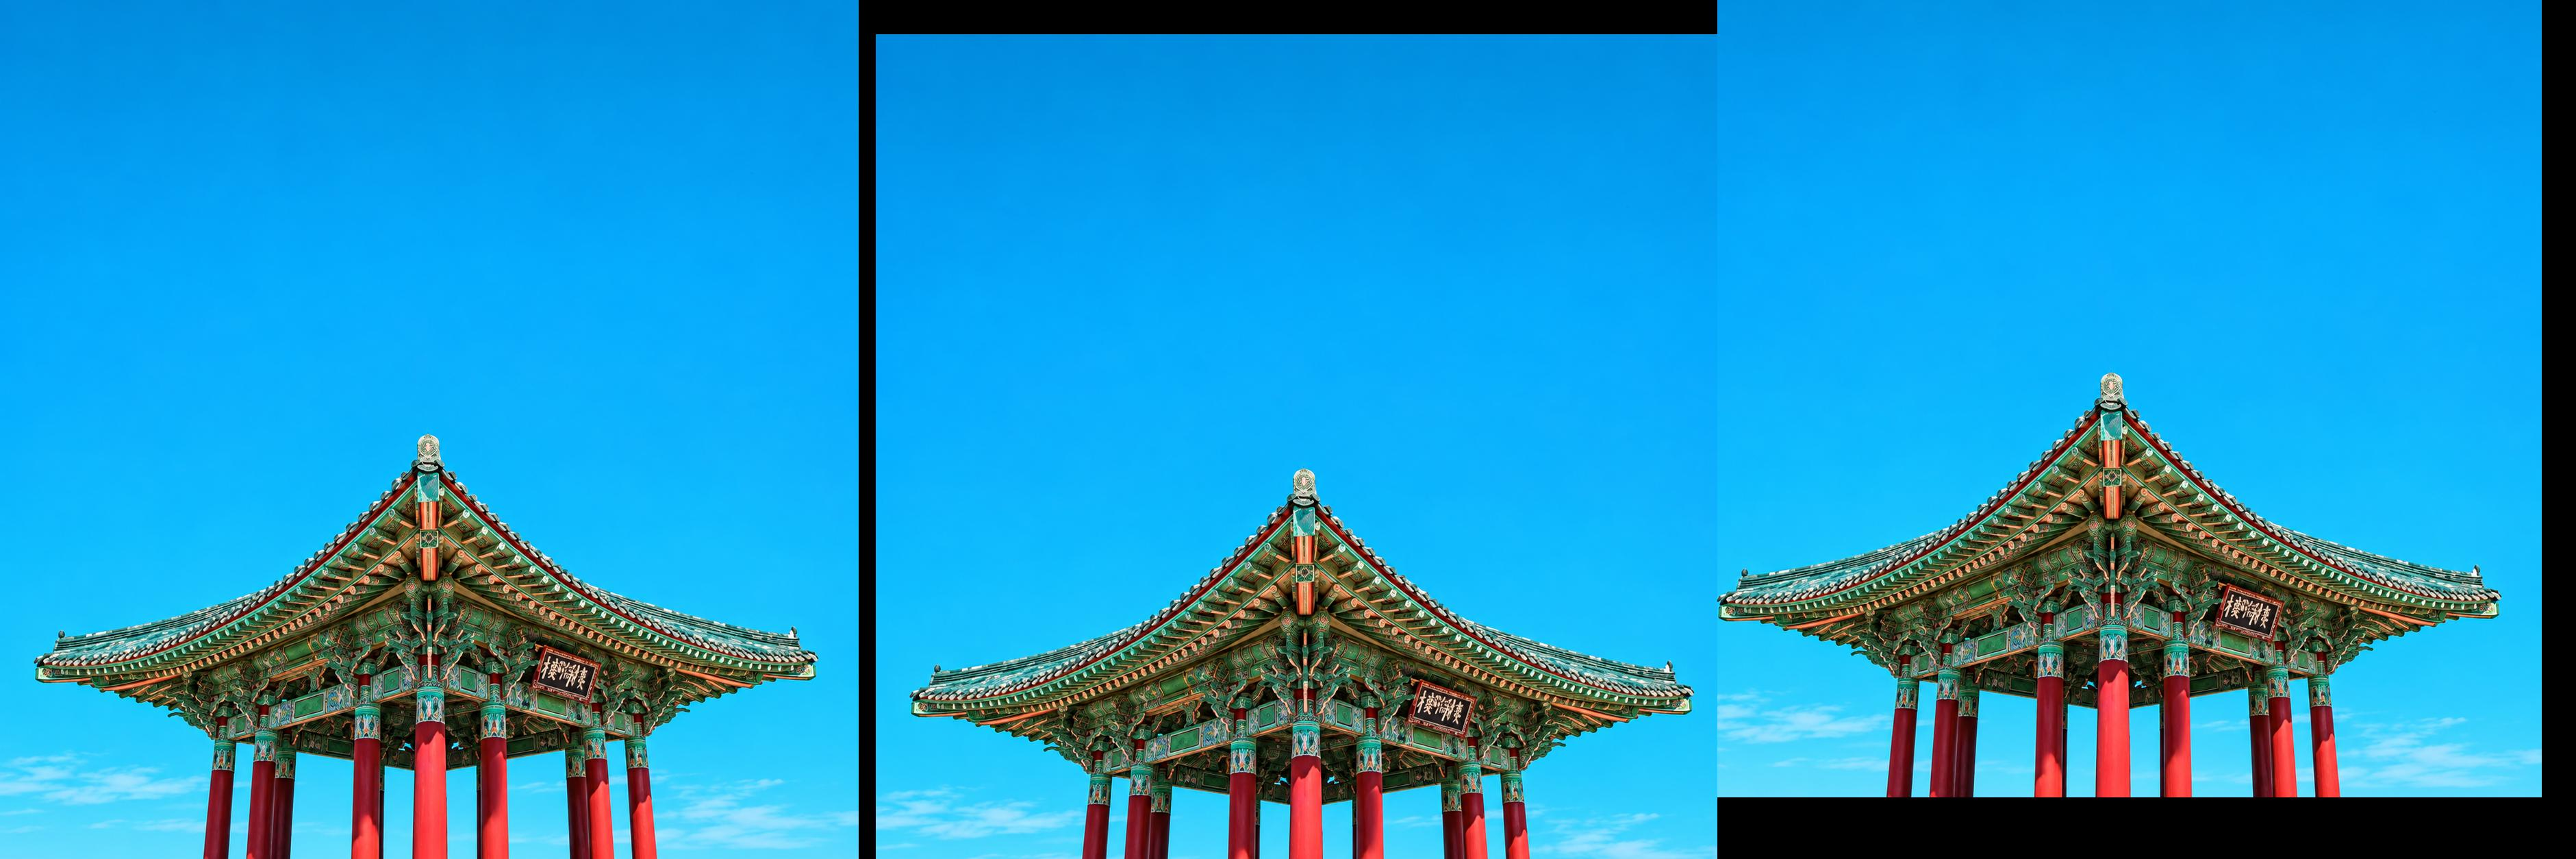

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/building300x200.jpg')
(height, width, channel) = image.shape[:]

# 이동변환 넘파이 매트릭스
# [[1, 0, translateX],
# [0, 1, translateY]]

M = np.float32([[1, 0, 25],
                [0, 1, 50]])
shiftedImage1 = cv2.warpAffine(image, M, (width,height))


M = np.float32([[1, 0, -50],
                [0, 1, -90]])
shiftedImage2 = cv2.warpAffine(image, M, (width,height))

shift_frame = cv2.hconcat([image, shiftedImage1,shiftedImage2])
cv2_imshow(shift_frame)

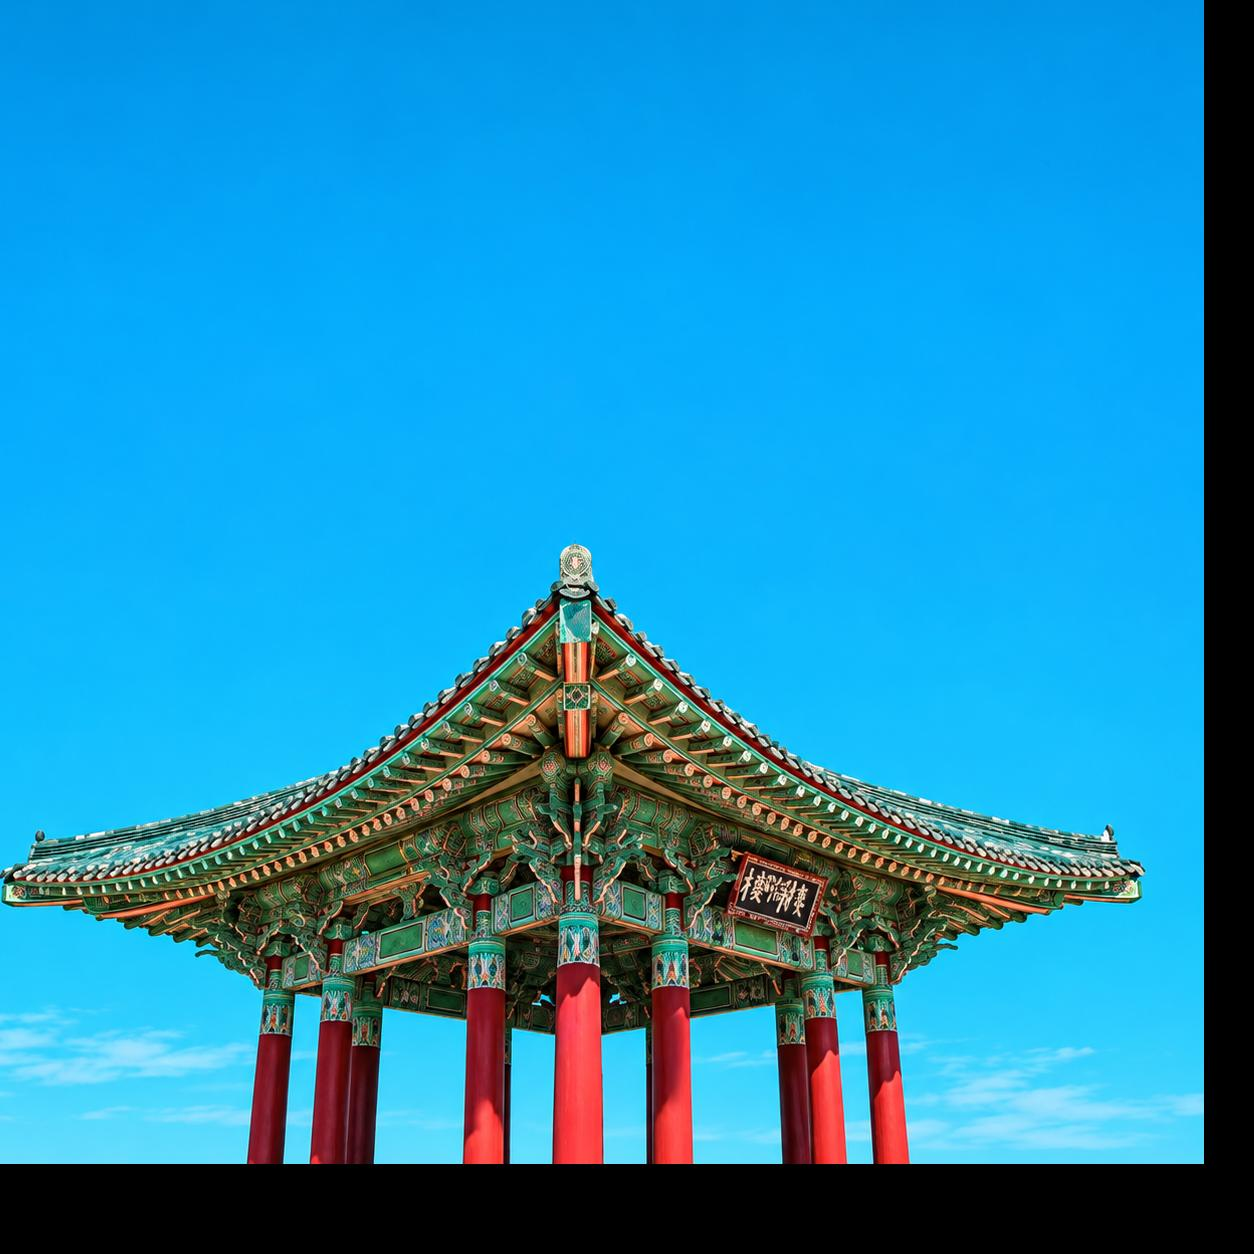

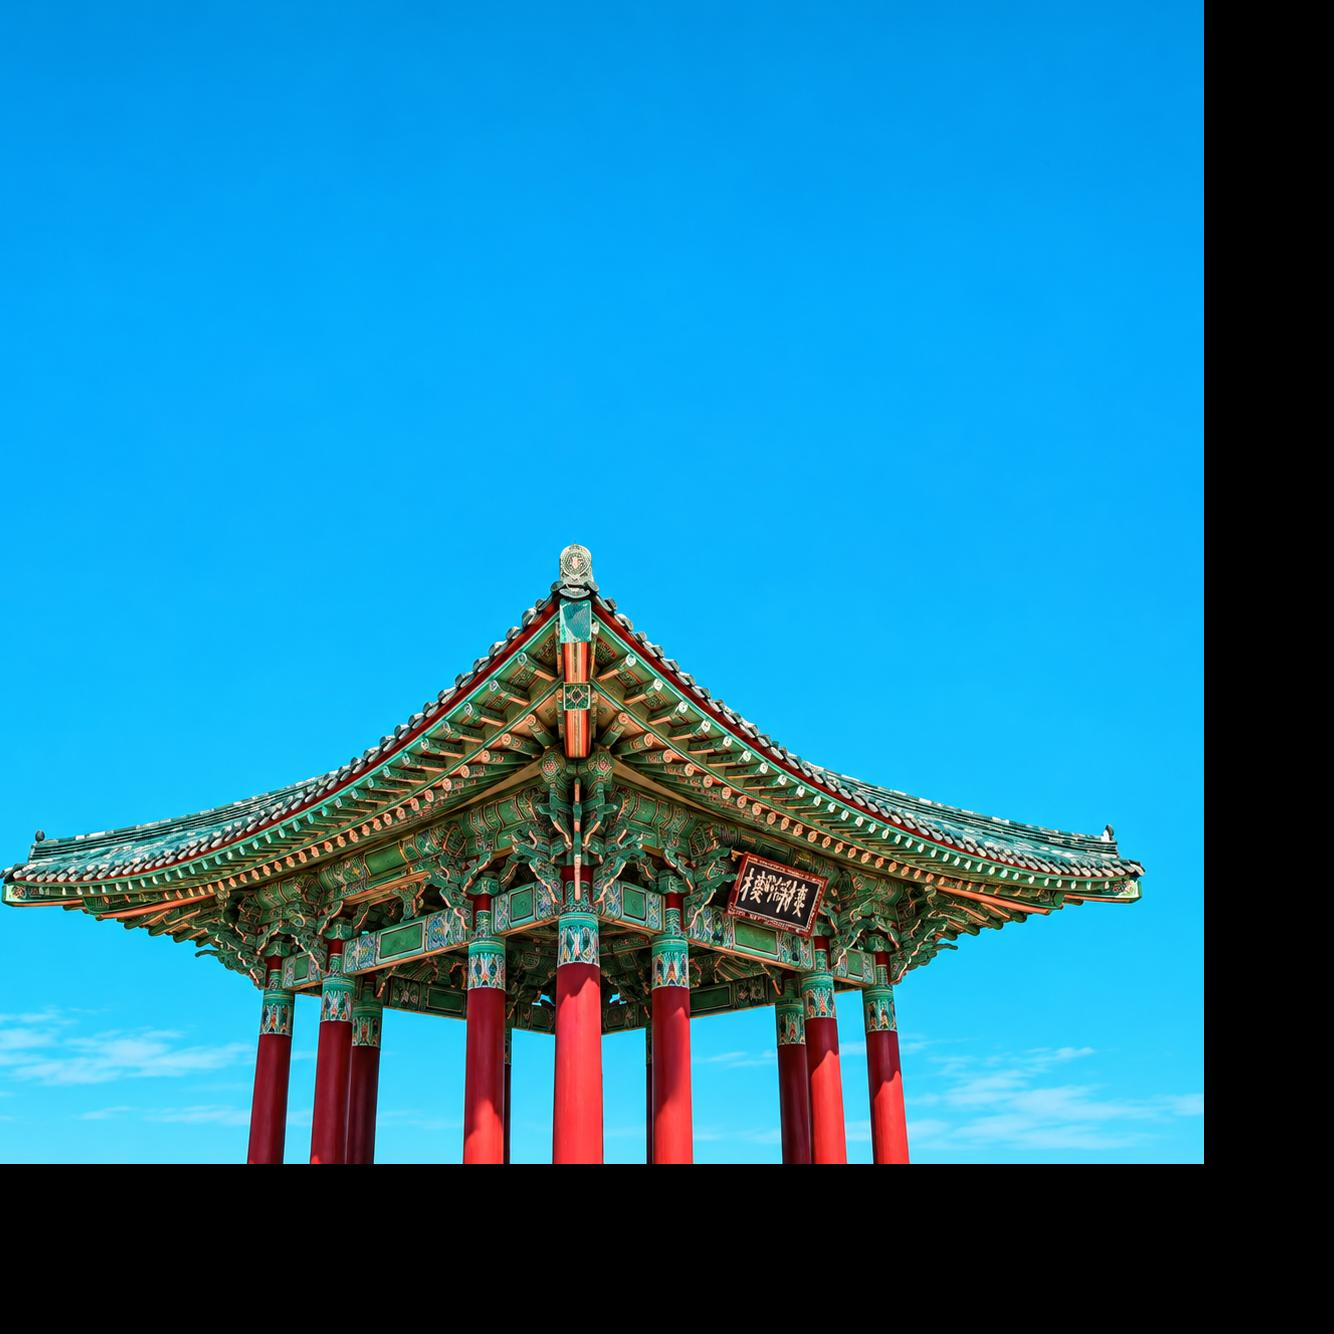

In [ ]:
shiftedImage = cv2.warpAffine(image, M, (width, height))
extendedImage = cv2.warpAffine(image, M, (width+80, height+80))

cv2_imshow(shiftedImage)
cv2_imshow(extendedImage)

**01.2 전단변환(Shear Transformation)**

```
cv2.warpAffine(srcImage,matrix,(width,height))
```

<br>
전단변환의 Affline Matrix:

$$
\mathbf{M}
=
\begin{bmatrix}
    1  &S_x    &0 \\
   S_y    &1   &0  \\
\end{bmatrix}
$$


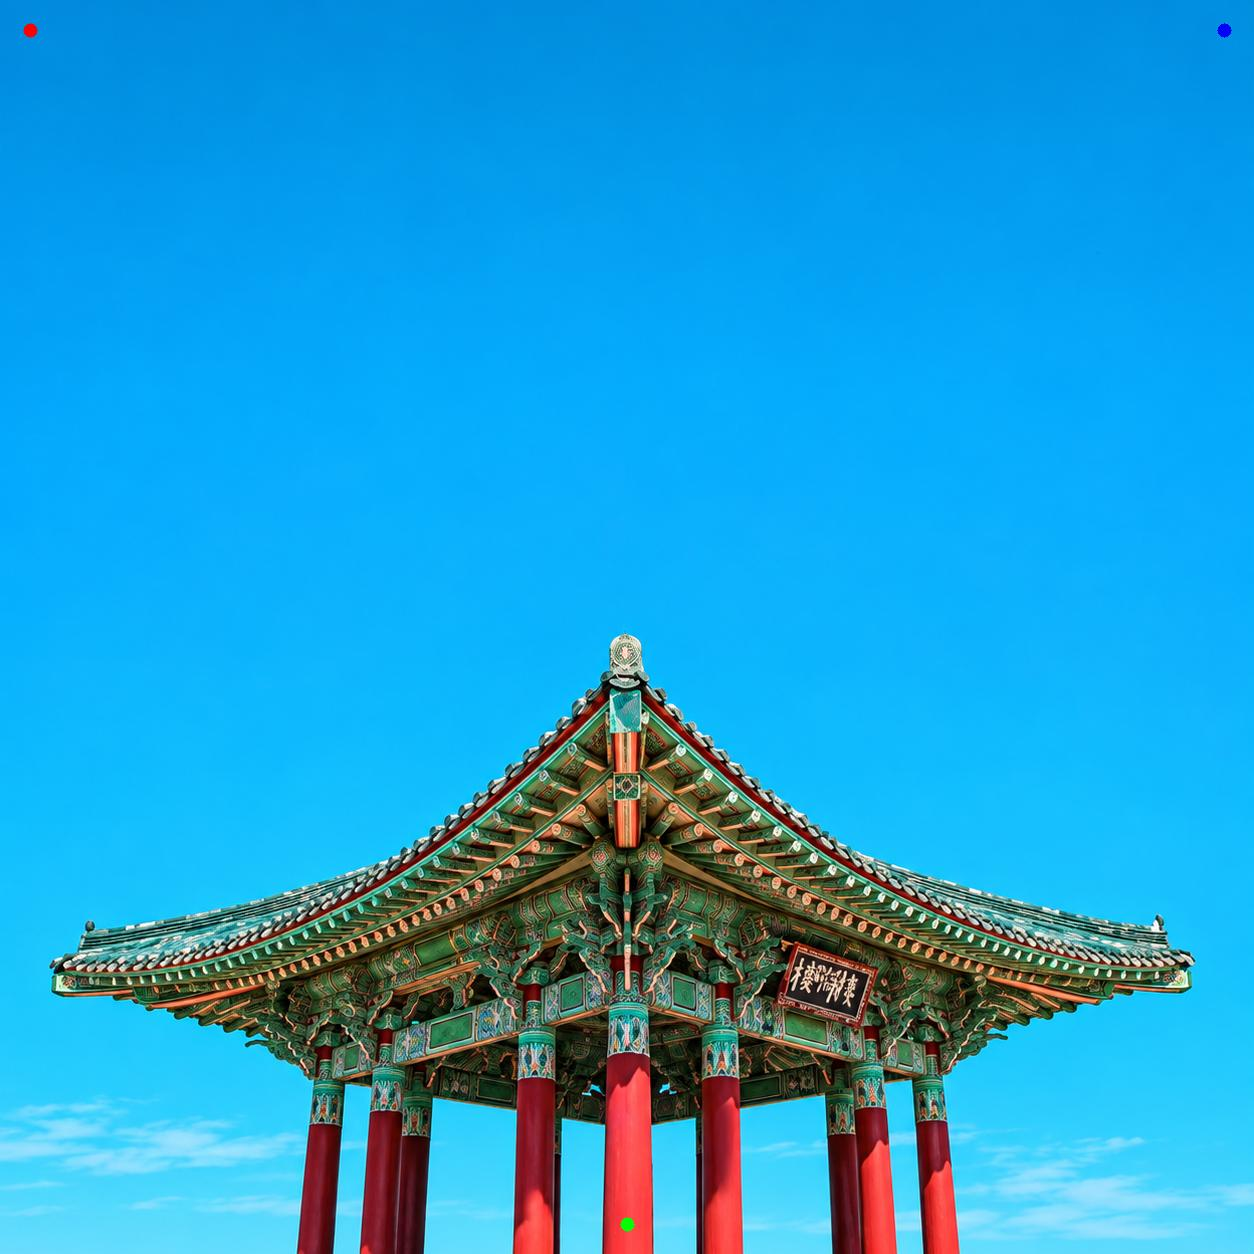

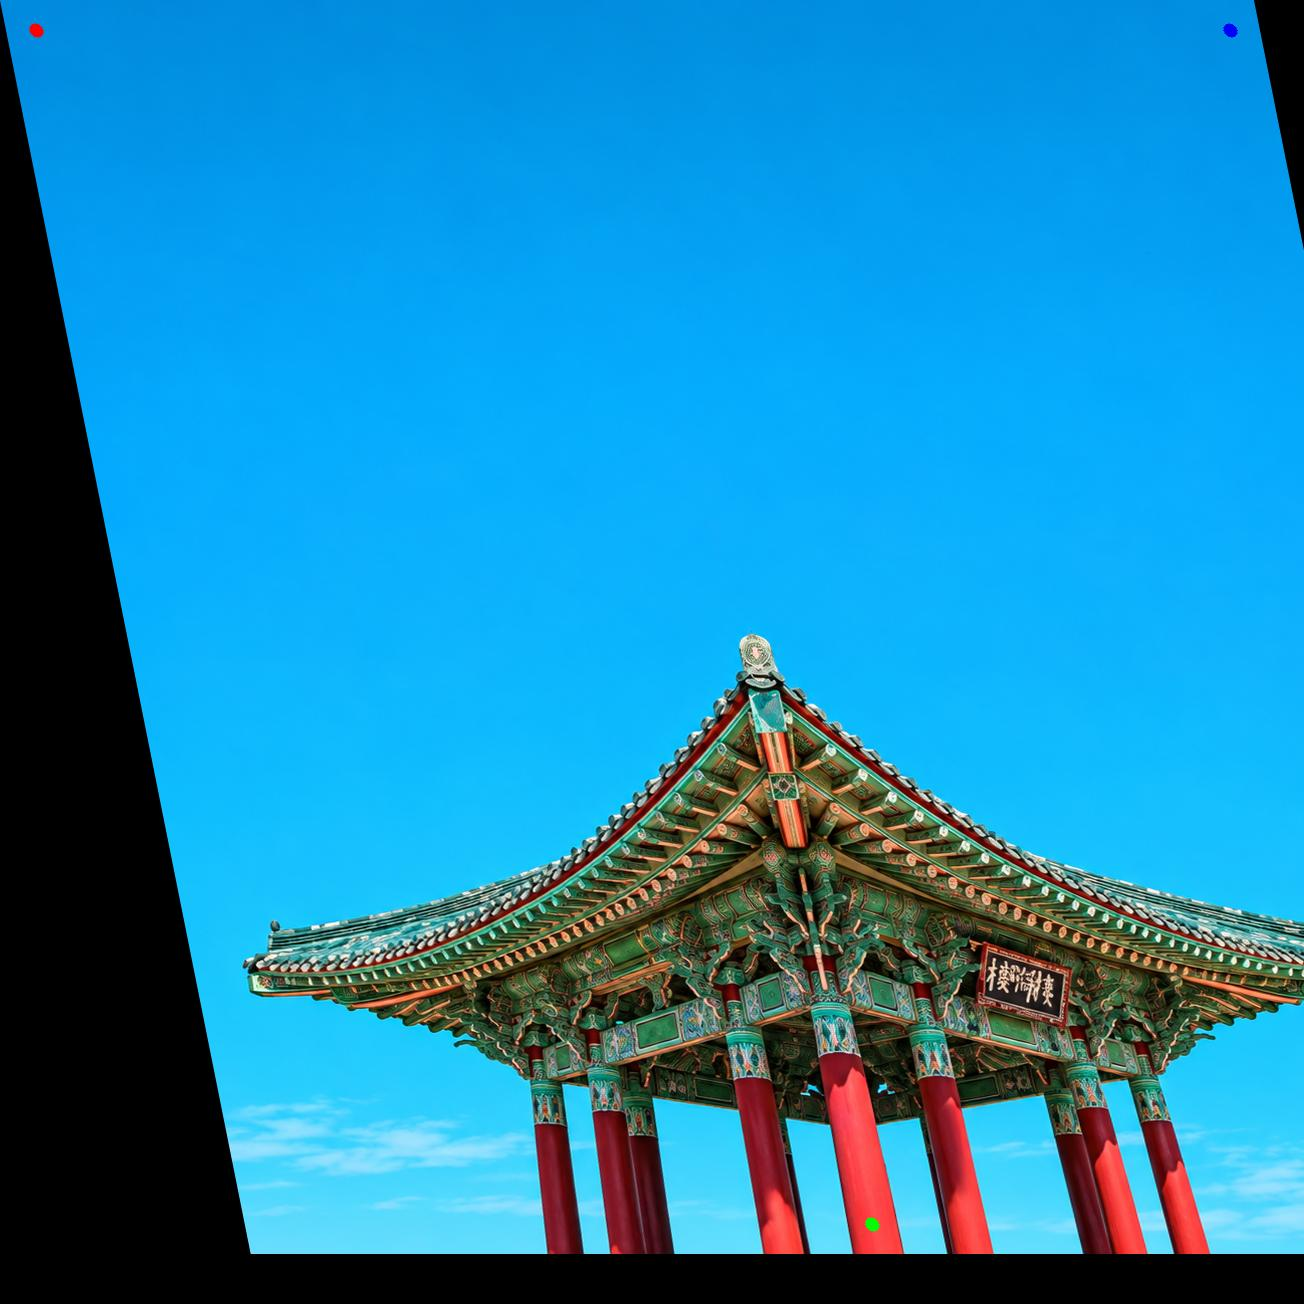

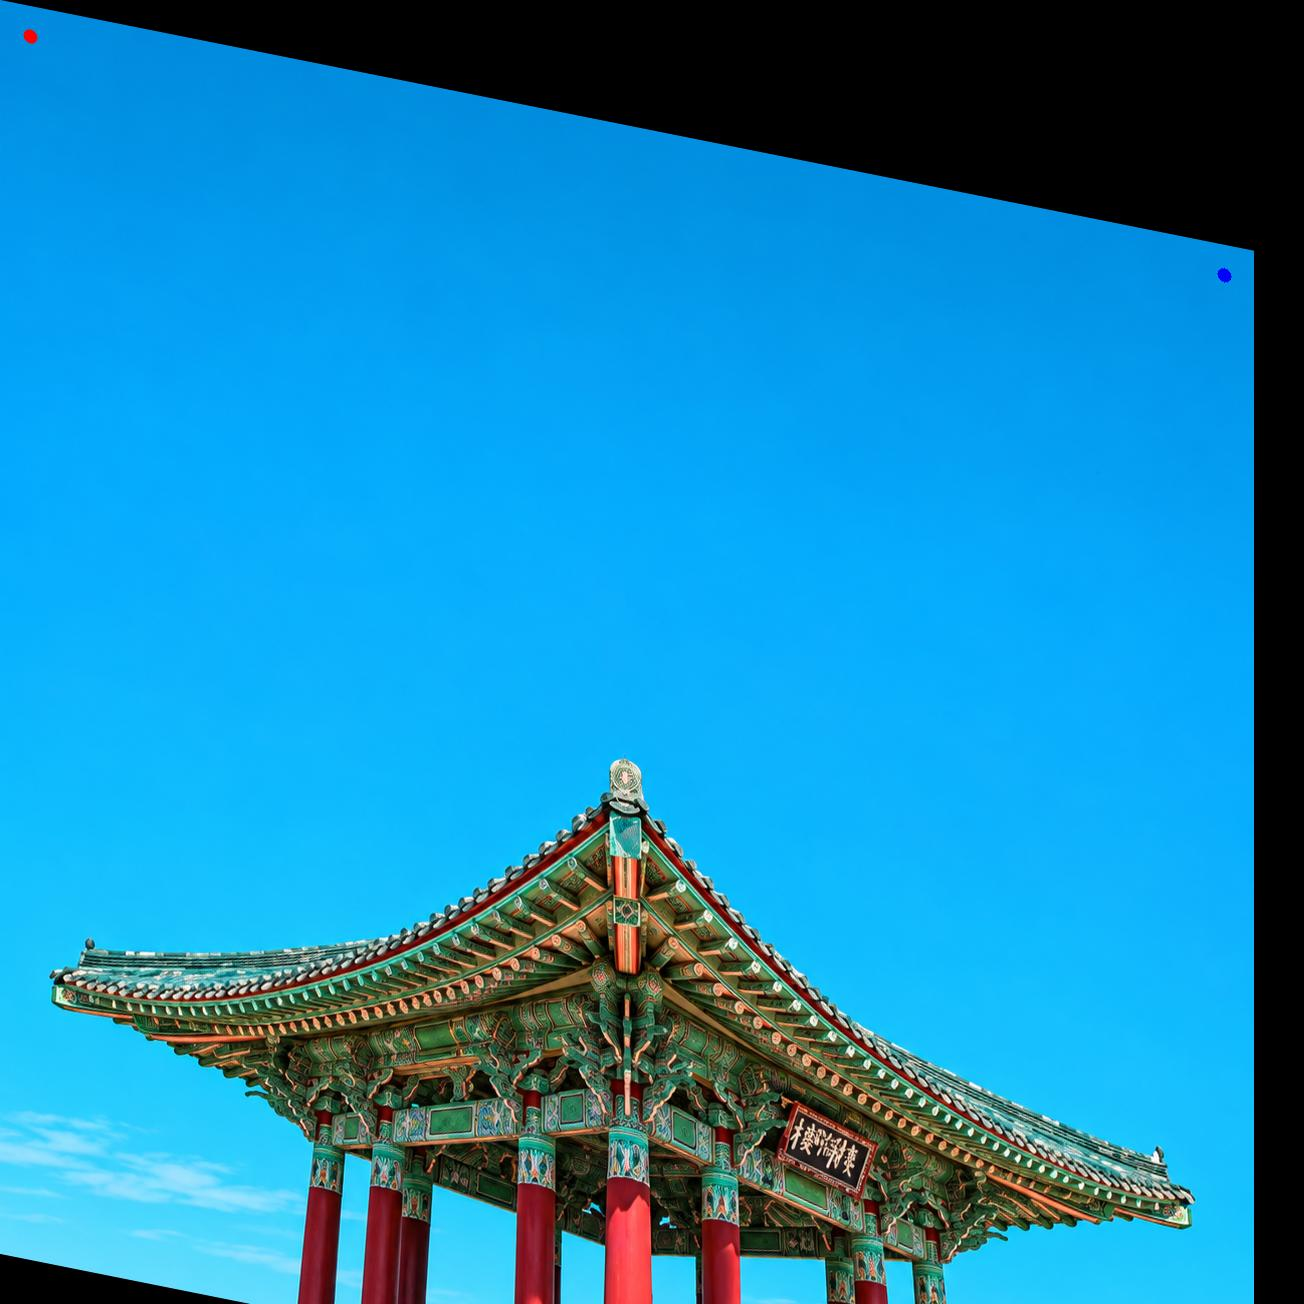

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/building300x200.jpg')
(height, width, channel) = image.shape[:]

# 이미지에 점 세 개 표시
cv2.circle(image, (30,30), 7, (0,0,255), -1)
cv2.circle(image, (width//2,height-30), 7, (0,255,0), -1)
cv2.circle(image, (width-30,30), 7, (255,0,0), -1)
cv2_imshow(image)


# 전단변환 넘파이 매트릭스
# [[1, shearX, 0],
# [shearY,  1, 0]]

M = np.float32([[1, 0.2, 0],
                [0, 1, 0]])
shiftedImage = cv2.warpAffine(image, M, (width+50,height+50))
cv2_imshow(shiftedImage)

M = np.float32([[1, 0, 0],
                [0.2, 1, 0]])
shiftedImage = cv2.warpAffine(image, M, (width+50,height+50))
cv2_imshow(shiftedImage)

**01.3 크기 변환(Scale Transformation)**

1. 원본 이미지 사이즈 내에서 크기 변환

  ```
  cv2.warpAffine(srcImage,matrix,(width,height))
  ```

  크기변환의 Affine Matrix:

$$
\mathbf{M}
=
\begin{bmatrix}
  S_x &0 &0 \\
  0 &S_y &0 \\
\end{bmatrix}
$$


<br>

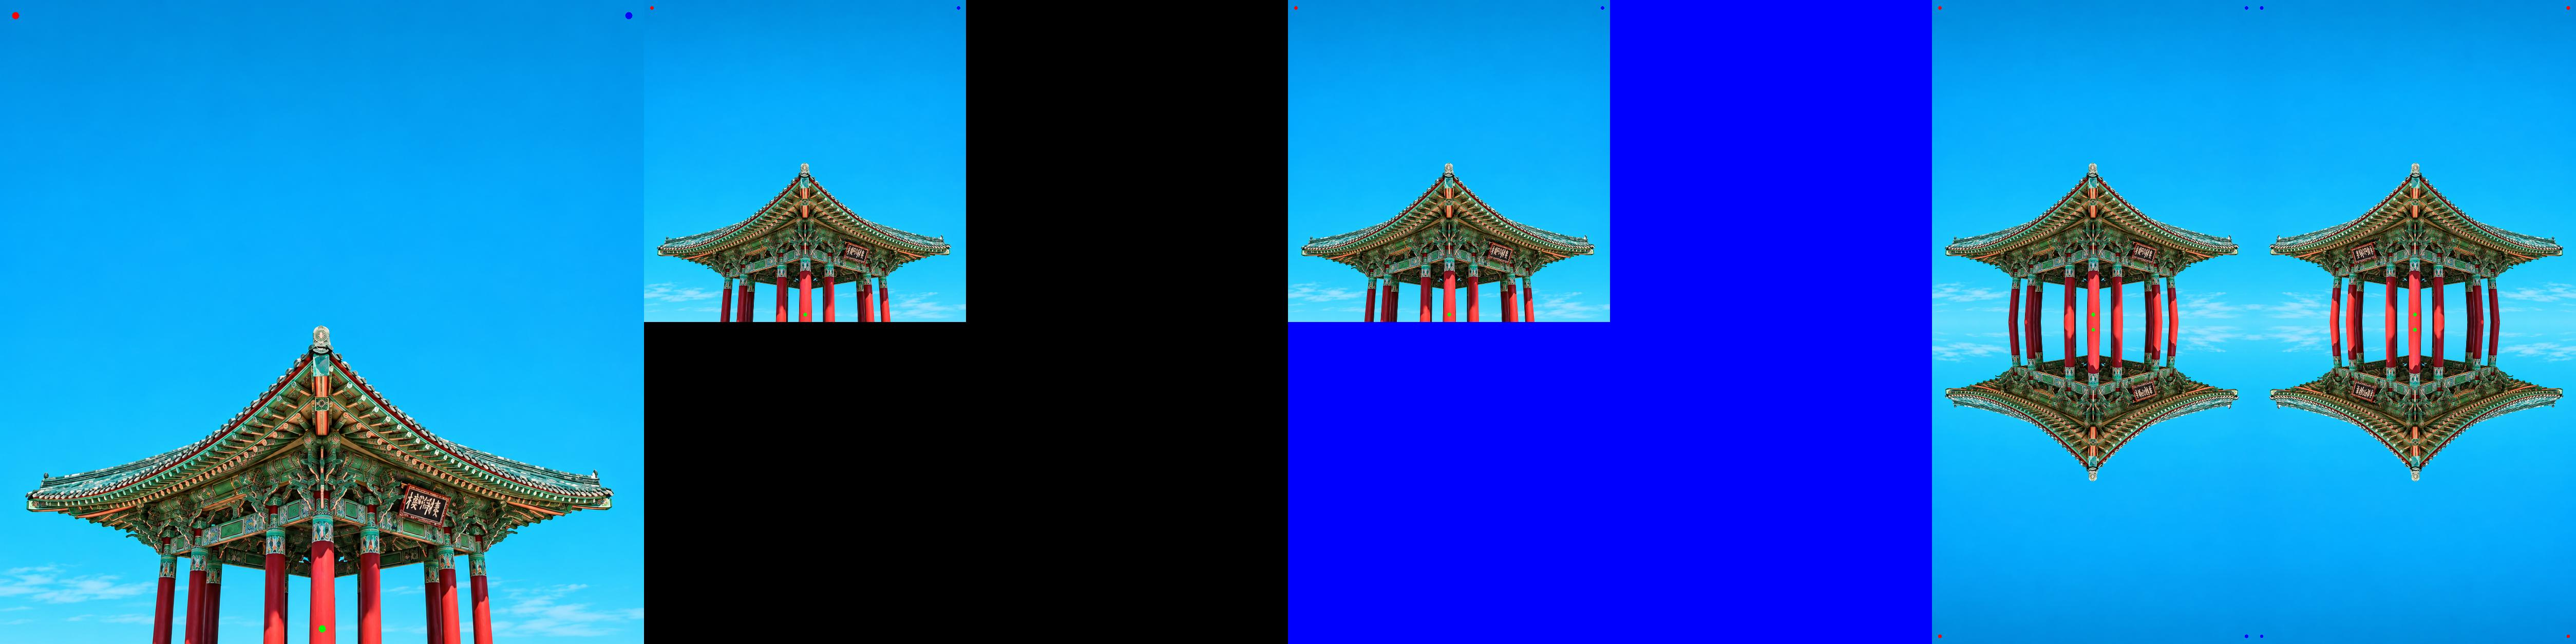

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/building300x200.jpg')
(height, width, channel) = image.shape[:]

# 이미지에 점 세 개 표시
cv2.circle(image, (30,30), 7, (0,0,255), -1)
cv2.circle(image, (width//2,height-30), 7, (0,255,0), -1)
cv2.circle(image, (width-30,30), 7, (255,0,0), -1)


# 크기변환 넘파이 매트릭스
# [[scaleX, 0, 0],
# [0,  scaleY, 0]]


# 이미지 축소
M = np.float32([[0.5, 0, 0],
                [0, 0.5, 0]])
scaledImage1 = cv2.warpAffine(image, M, (width, height))

# 이미지가 없는 부분을 파랑색으로 보정
scaledImage2 = cv2.warpAffine(image, M, (width, height), None, cv2.INTER_LINEAR, cv2.BORDER_CONSTANT, (255,0,0) )

# 이미지가 없는 부분에 원본을 반사 시켜서 보정
scaledImage3 = cv2.warpAffine(image, M, (width, height), None, cv2.INTER_LINEAR, cv2.BORDER_REFLECT)

shift_frame = cv2.hconcat([image, scaledImage1, scaledImage2, scaledImage3])
cv2_imshow(shift_frame)



2. resize 함수를 사용한 이미지 크기 변환
  ```
  cv2.resize(srcImage, dimension, fx, fy, interpolation)
  ```
  Parameters:
  - srcImage – 변환할 이미지
  - dimension – 튜플형식의 이미지 사이즈 (가로,세로)
  - fx – 가로 사이즈의 배수 (2배: 2, 0.5배: 0.5)
  - fy – 세로 사이즈의 배수
  - interpolation(보간법) - 이미지 크기가 변할 때 픽셀 사이 값을 결정
    - cv2.INTER_AREA
    - cv2.INTER_CUBIC
    - cv2.INTER_LINEAR


(1254, 1254, 3)


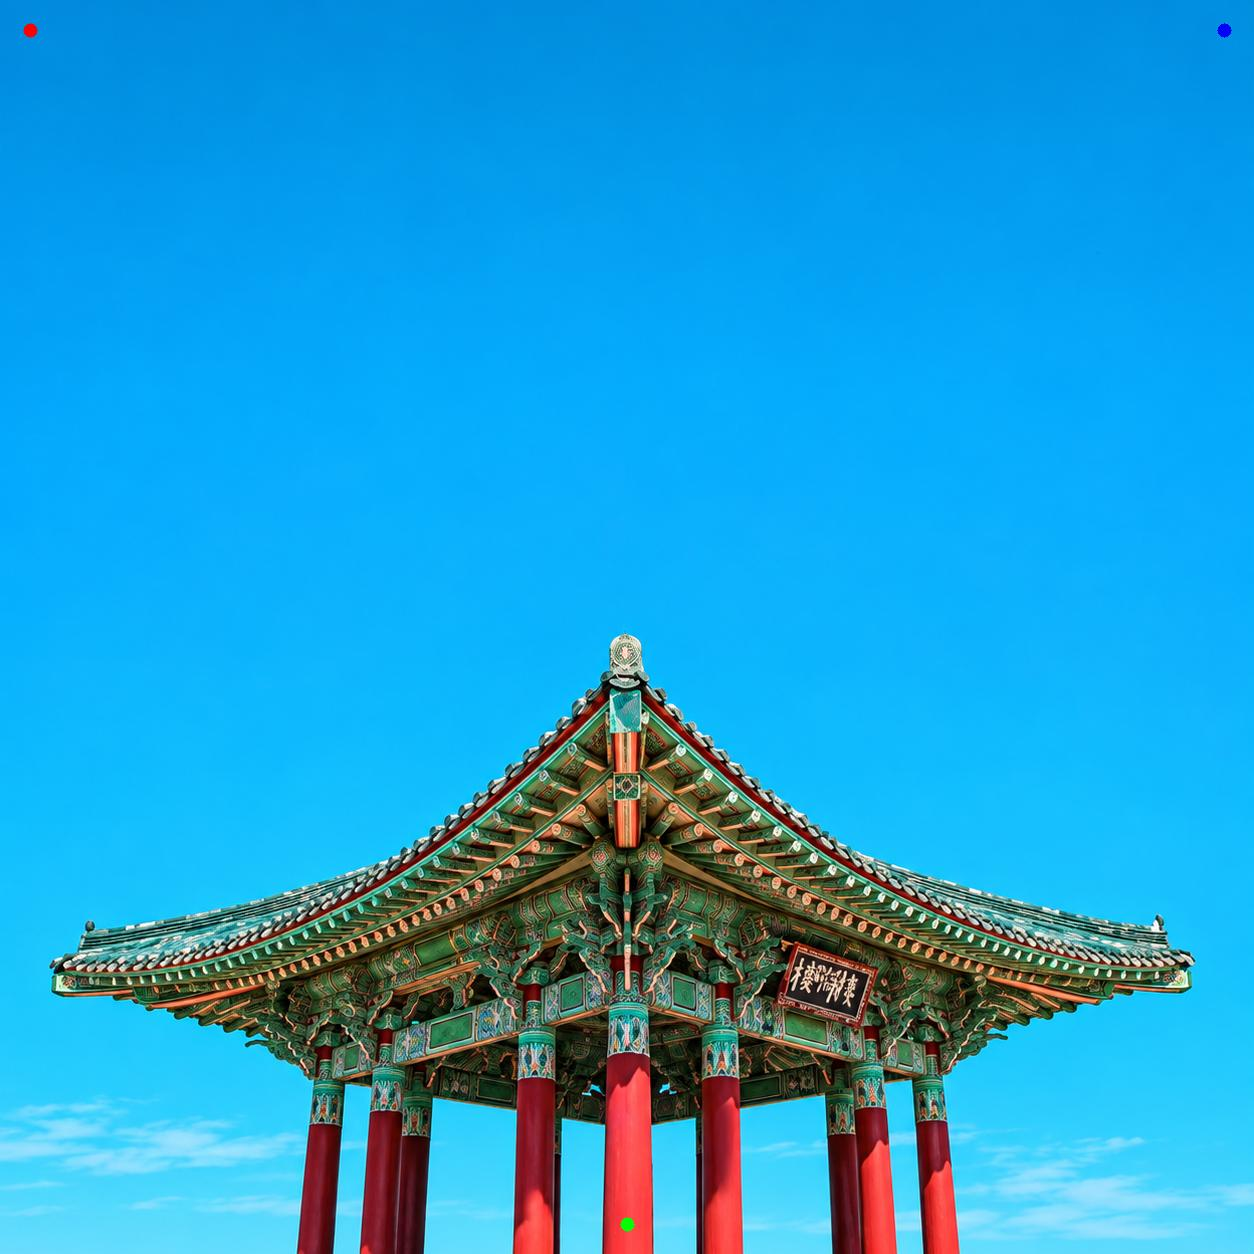

(100, 300, 3)


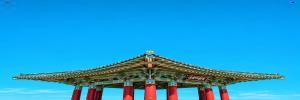

(627, 627, 3)


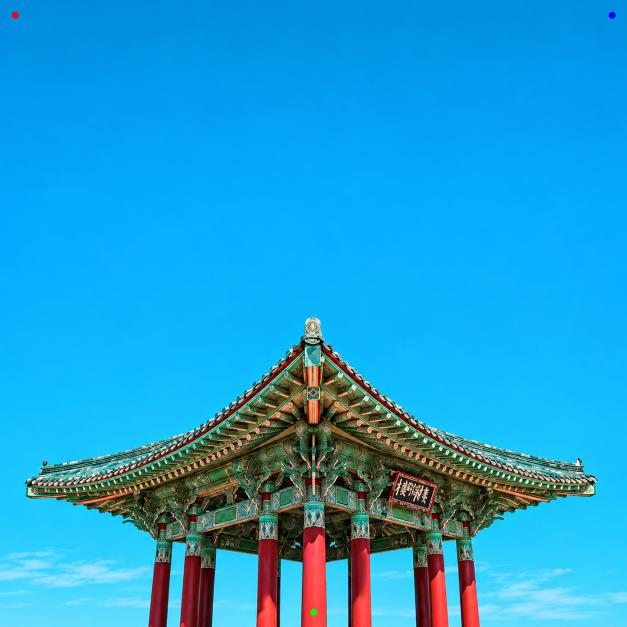

(1881, 1881, 3)


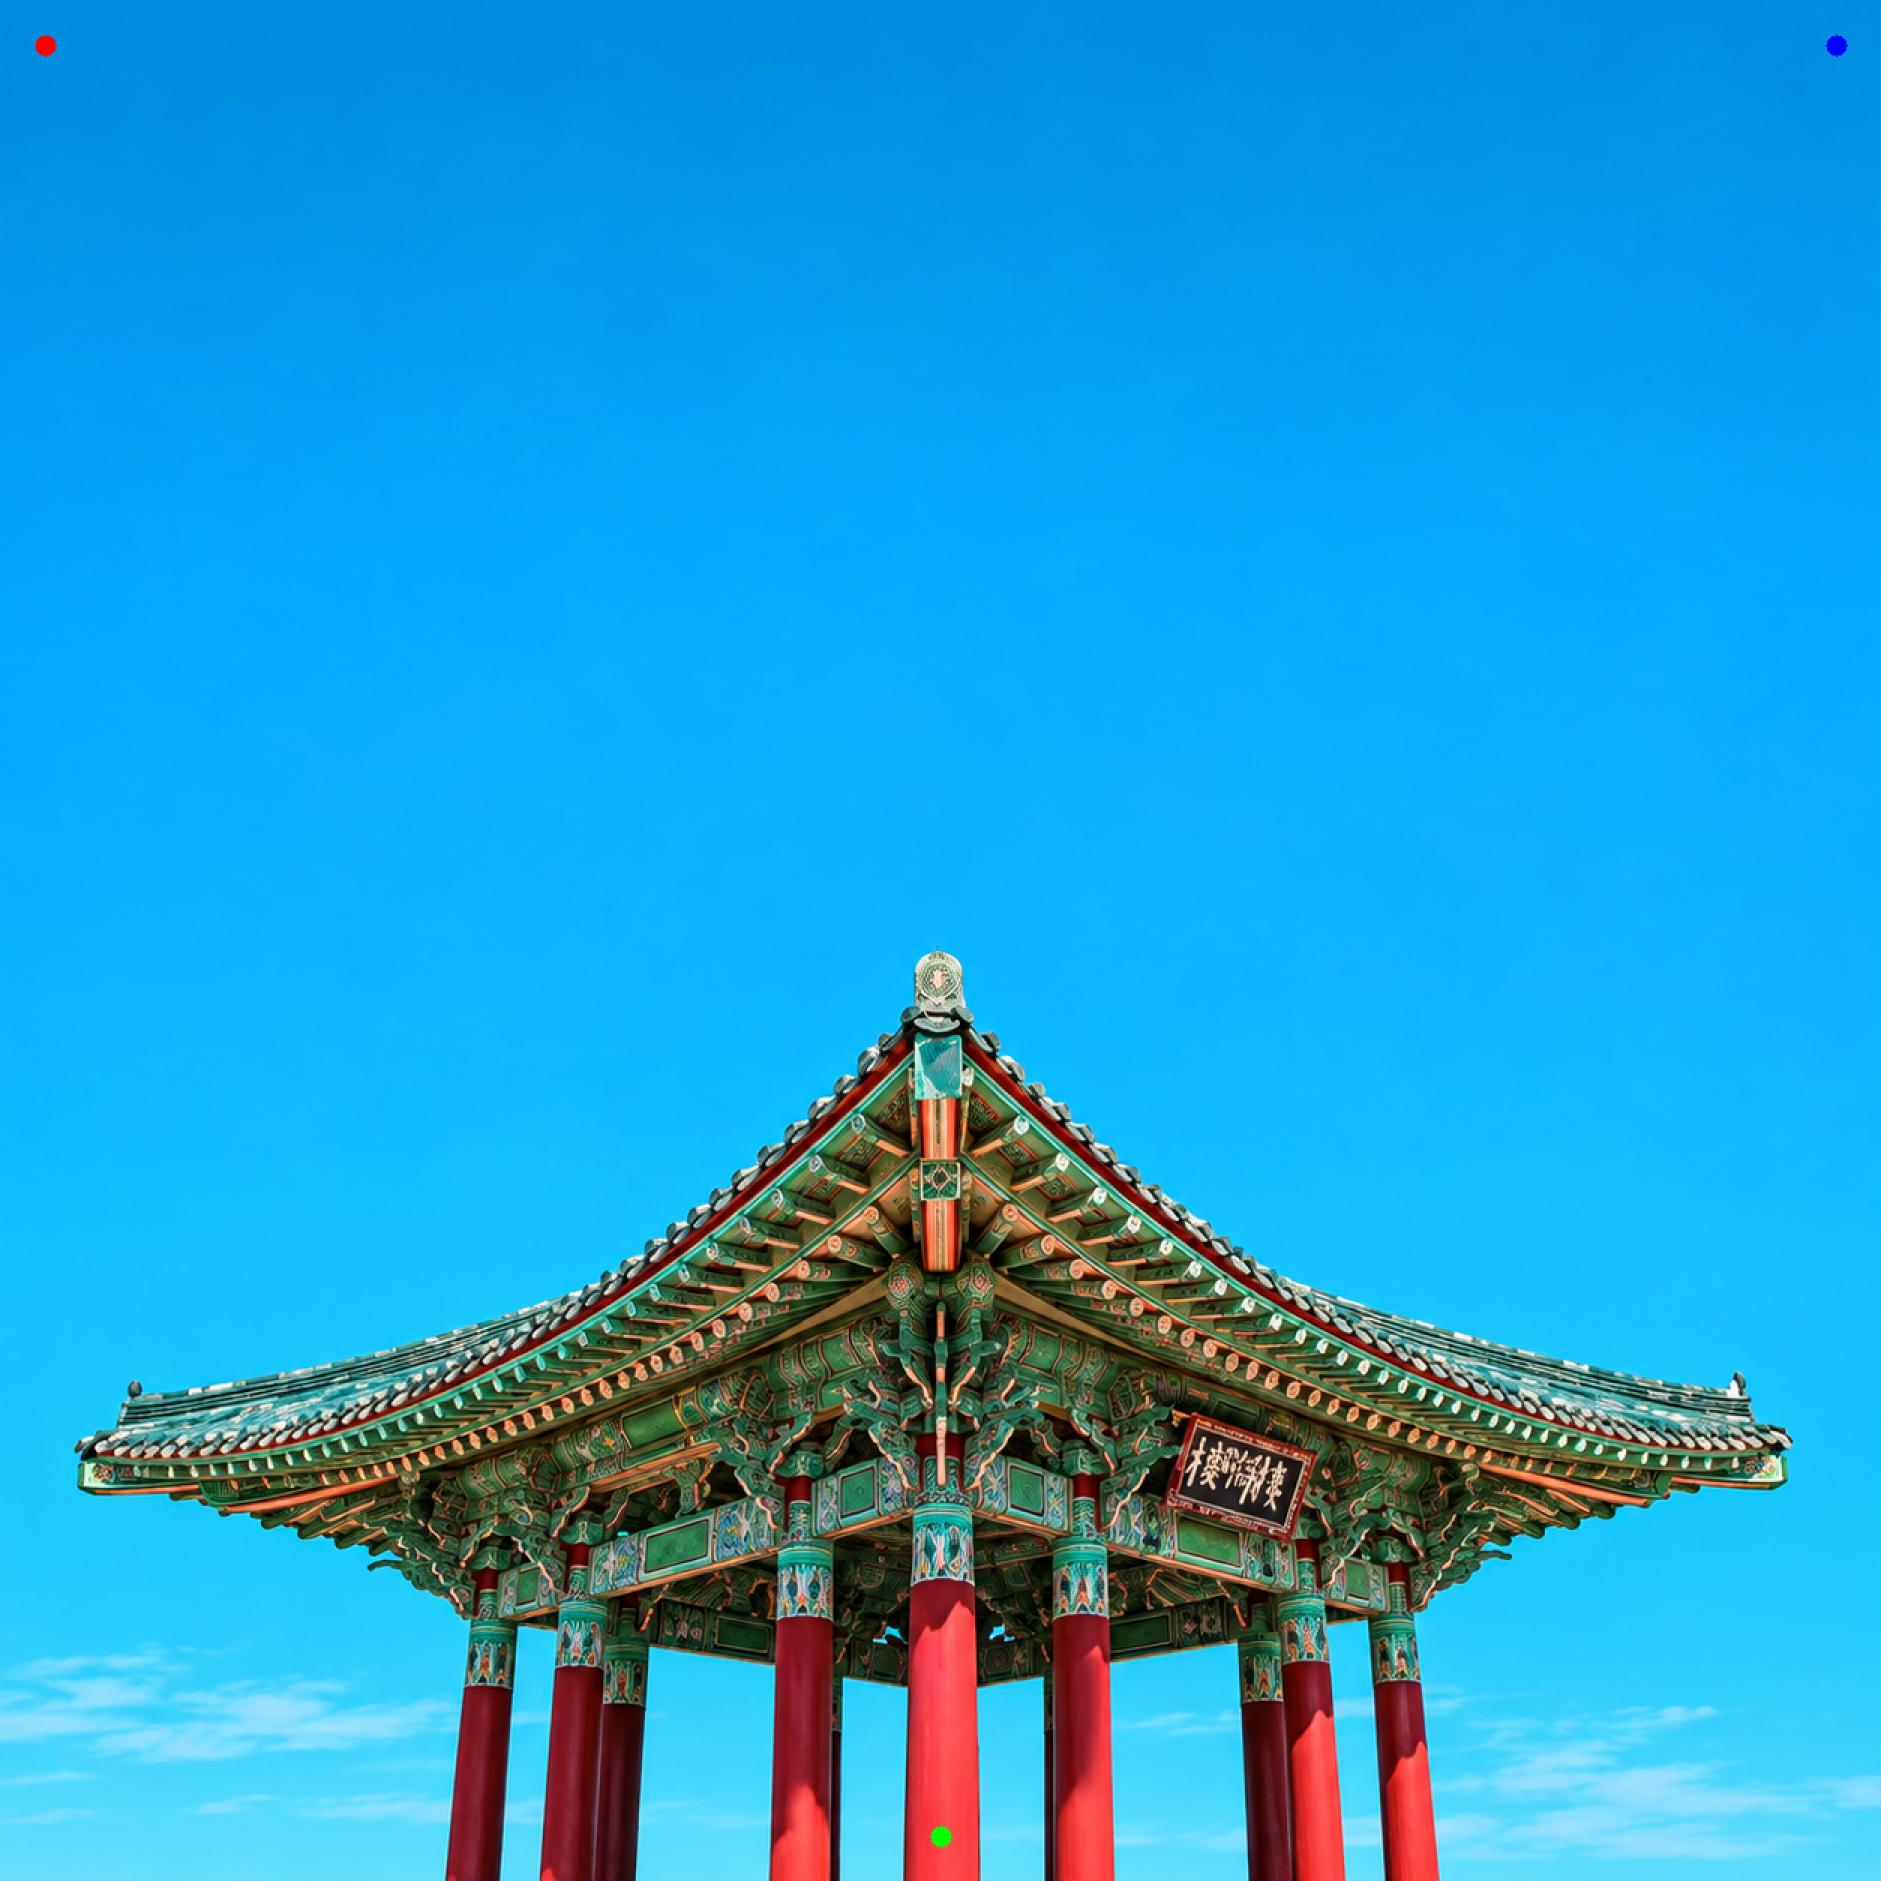

(627, 627, 3)


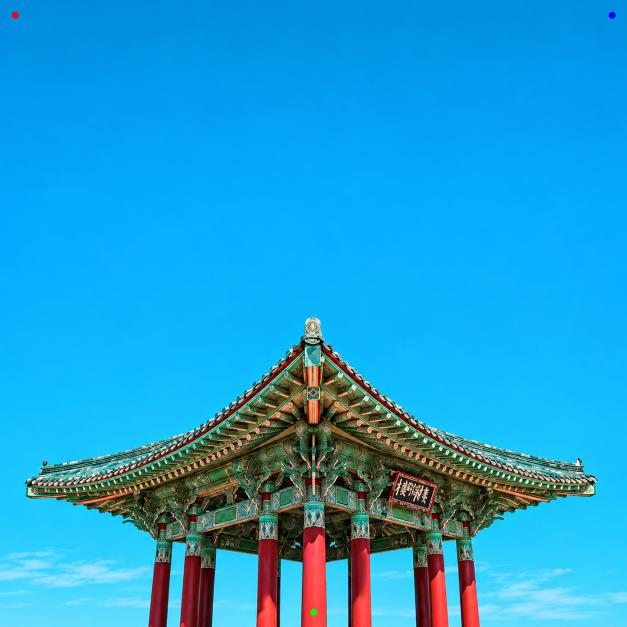

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/building300x200.jpg')
(height, width, channel) = image.shape[:]

# 이미지에 점 세 개 표시
cv2.circle(image, (30,30), 7, (0,0,255), -1)
cv2.circle(image, (width//2,height-30), 7, (0,255,0), -1)
cv2.circle(image, (width-30,30), 7, (255,0,0), -1)

print(image.shape)
cv2_imshow(image)


# 확대/축소할 가로, 세로 크기를 지정
dimension = (300,100)
resizedImage = cv2.resize(image, dimension, interpolation = cv2.INTER_AREA)

print(resizedImage.shape)
cv2_imshow(resizedImage)


# 비율을 맞춰 축소하기
scale = 0.5
dimension = (int(width*scale),int(height*scale))
resizedImage = cv2.resize(image, dimension, interpolation = cv2.INTER_AREA)

print(resizedImage.shape)
cv2_imshow(resizedImage)


# 비율을 맞춰 확대하기
scale = 1.5
dimension = (int(width*scale),int(height*scale))
resizedImage = cv2.resize(image, dimension, interpolation = cv2.INTER_AREA)

print(resizedImage.shape)
cv2_imshow(resizedImage)


# 비율을 맞춰 크기변환하기
resizedImage = cv2.resize(image, None, fx=0.5, fy=0.5)
print(resizedImage.shape)
cv2_imshow(resizedImage)

**01.4 회전 변환(Rotation Transformation)**

1. 어파인 매트릭스를 사용한 회전
  
  ```
  cv2.warpAffine(srcImage,matrix,(width,height))
  ```

  회전변환의 Affine Matrix:

$$
\mathbf{M}
=
\begin{bmatrix}
    cos\theta   &sin\theta    &0 \\
    -sin\theta   &cos\theta   &0  \\
\end{bmatrix}
$$




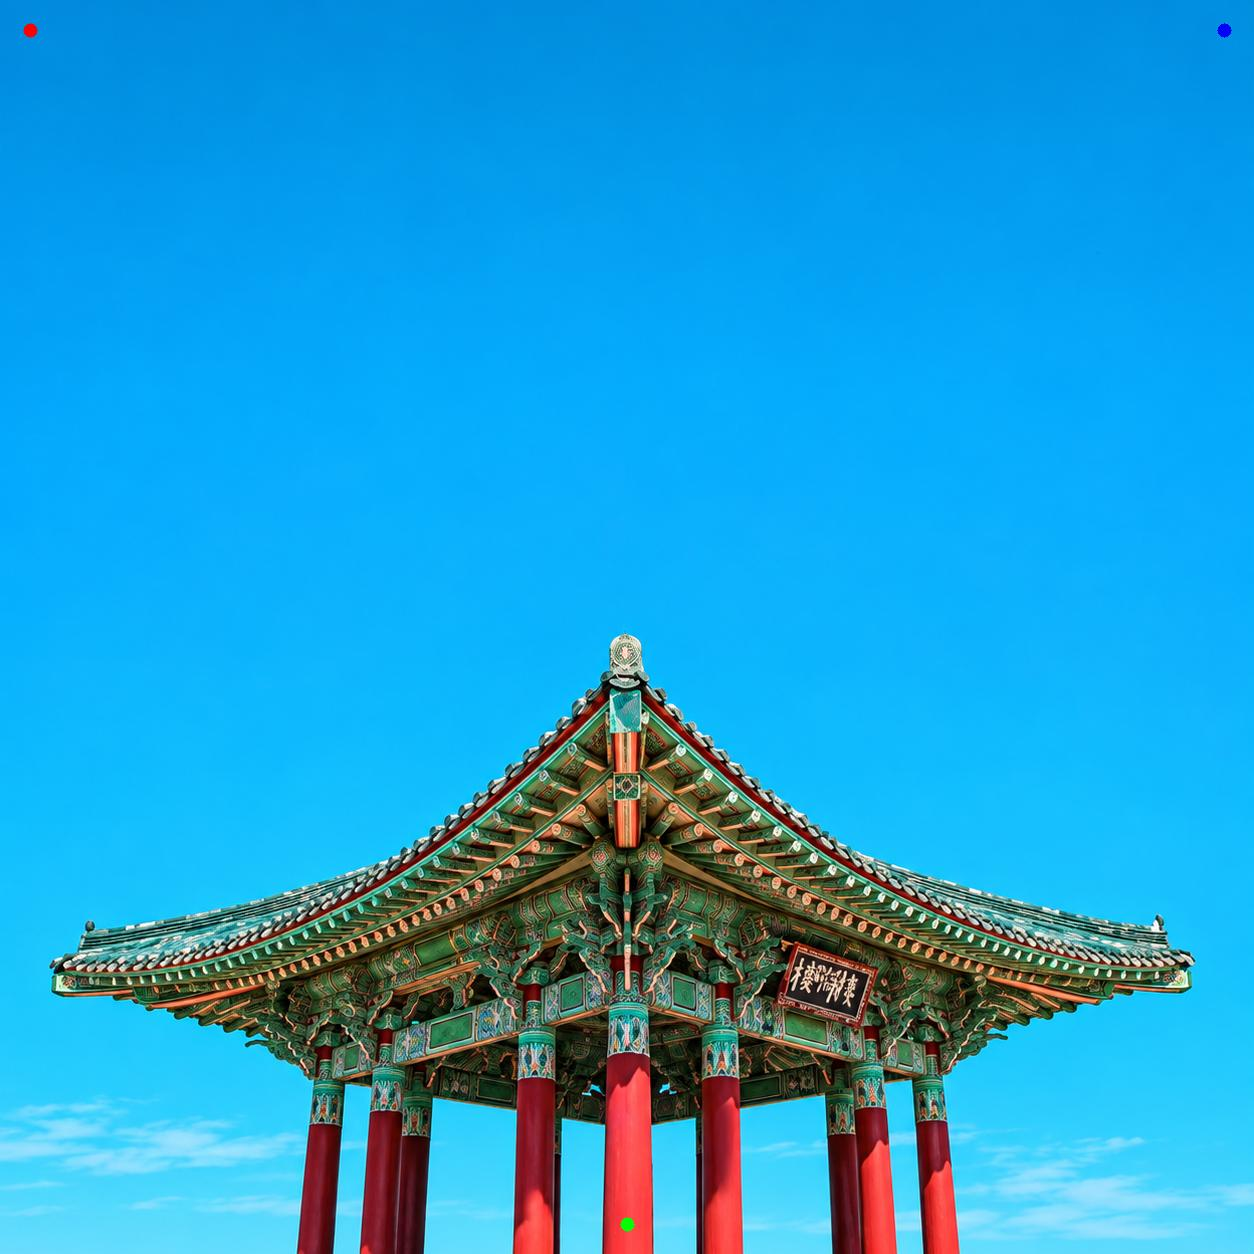

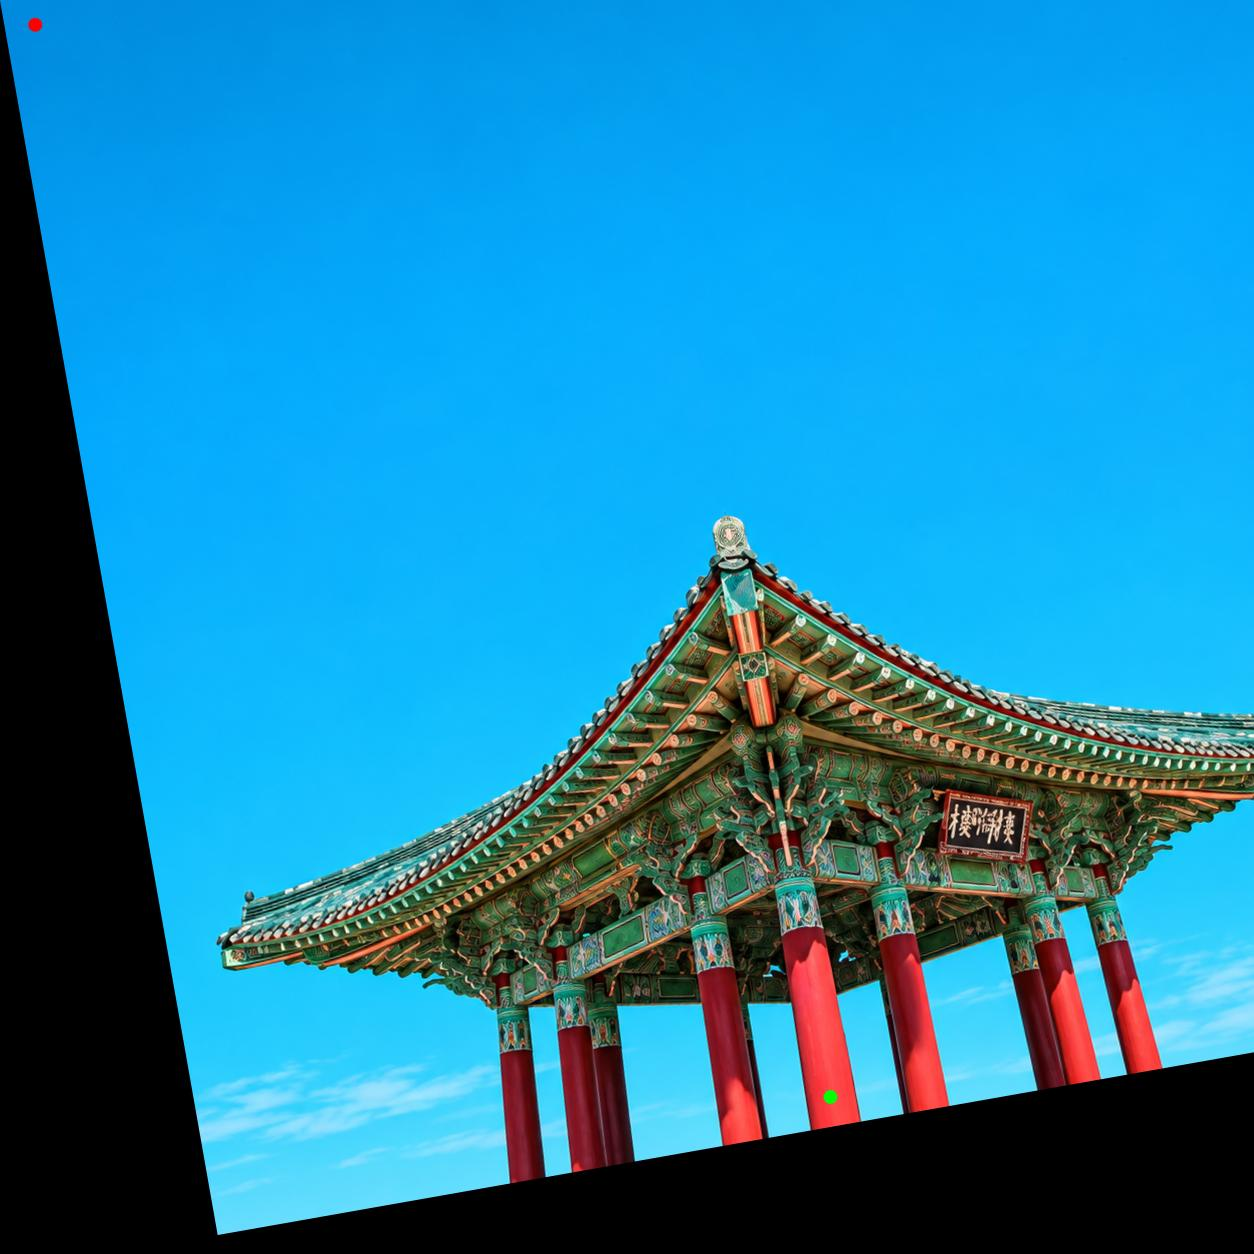

1. (0,0) rotation 
 [[ 0.9848077   0.17364818  0.        ]
 [-0.17364818  0.9848077   0.        ]]


In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/building300x200.jpg')
(height, width, channel) = image.shape[:]

# 이미지에 점 세 개 표시
cv2.circle(image, (30,30), 7, (0,0,255), -1)
cv2.circle(image, (width//2,height-30), 7, (0,255,0), -1)
cv2.circle(image, (width-30,30), 7, (255,0,0), -1)
cv2_imshow(image)

# 회전변환 넘파이 매트릭스
# [[𝑐𝑜𝑠𝜃, 𝑠𝑖𝑛𝜃, 0],
# [-𝑠𝑖𝑛𝜃, 𝑐𝑜𝑠𝜃, 0]]

degree = 10
sin = np.sin(np.deg2rad(degree))
cos = np.cos(np.deg2rad(degree))

M = np.float32([[cos, sin, 0],
                [-sin, cos, 0]])

shiftedImage = cv2.warpAffine(image, M, (width,height))
cv2_imshow(shiftedImage)

print("1. (0,0) rotation \n", M)

2. getRotationMatrix2D 함수를 사용해 회전하기

  ```
  cv2.getRotationMatrix2D(originPoint, angle, scale)
  ```



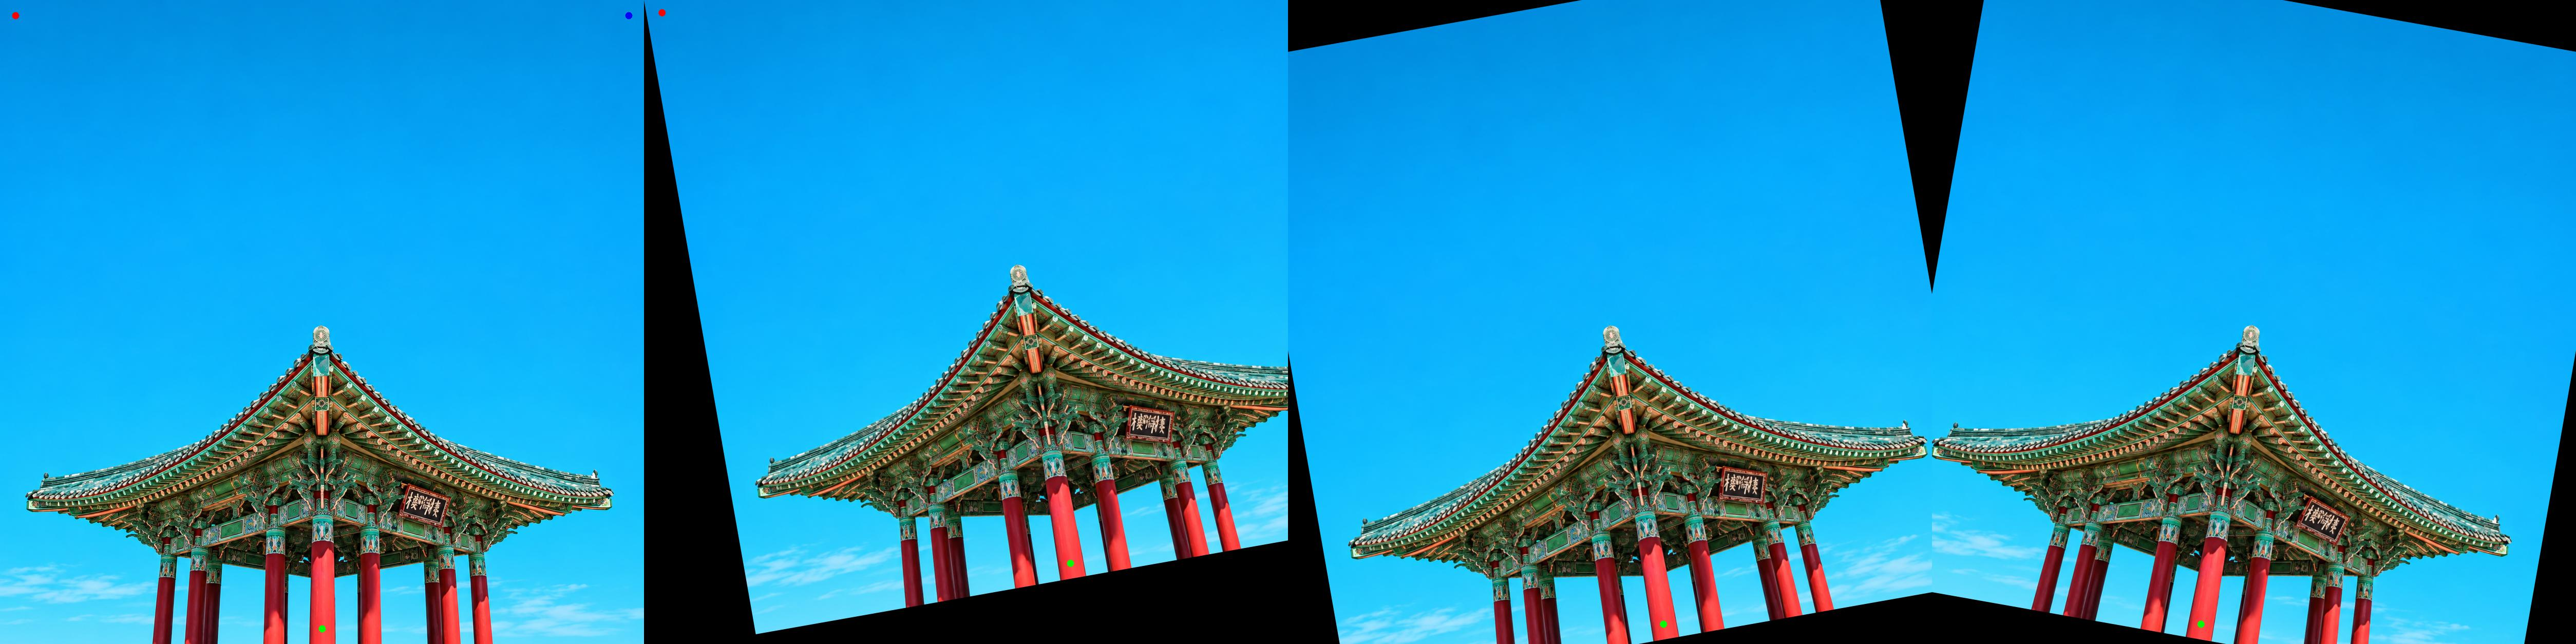

1. (0,0) rotation 
 [[ 0.98480775  0.17364818  0.        ]
 [-0.17364818  0.98480775  0.        ]]
2. (627, 627) rotation 
 [[  0.98480775   0.17364818 -99.35186854]
 [ -0.17364818   0.98480775 118.40294626]]
3. (627, 627) rotation 
 [[  0.98480775  -0.17364818 118.40294626]
 [  0.17364818   0.98480775 -99.35186854]]


In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/building300x200.jpg')

(height, width, channel) = image.shape[:]
center = (width//2, height//2)
topLeft =(0,0)

degree = 10


# 이미지에 점 세 개 표시
cv2.circle(image, (30,30), 7, (0,0,255), -1)
cv2.circle(image, (width//2,height-30), 7, (0,255,0), -1)
cv2.circle(image, (width-30,30), 7, (255,0,0), -1)


# (0,0)을 기준으로 반시계방향 회전
M_topLeft = cv2.getRotationMatrix2D(topLeft, degree, 1)
topLeftRotated = cv2.warpAffine(image,M_topLeft,(width,height))

# 이미지의 중심을 기준으로 반시계방향 회전
M_center = cv2.getRotationMatrix2D(center, degree, 1)
centerRotated = cv2.warpAffine(image, M_center,(width,height))

# 이미지의 중심을 기준으로 시계방향 회전
M_invCenter = cv2.getRotationMatrix2D(center, -degree, 1)
centerInvRotated = cv2.warpAffine(image, M_invCenter,(width,height))

rotate_frame = cv2.hconcat([image, topLeftRotated,centerRotated,centerInvRotated])
cv2_imshow(rotate_frame)

print("1. (0,0) rotation \n", M_topLeft)
print("2.",center,"rotation \n", M_center)
print("3.",center,"rotation \n", M_invCenter)

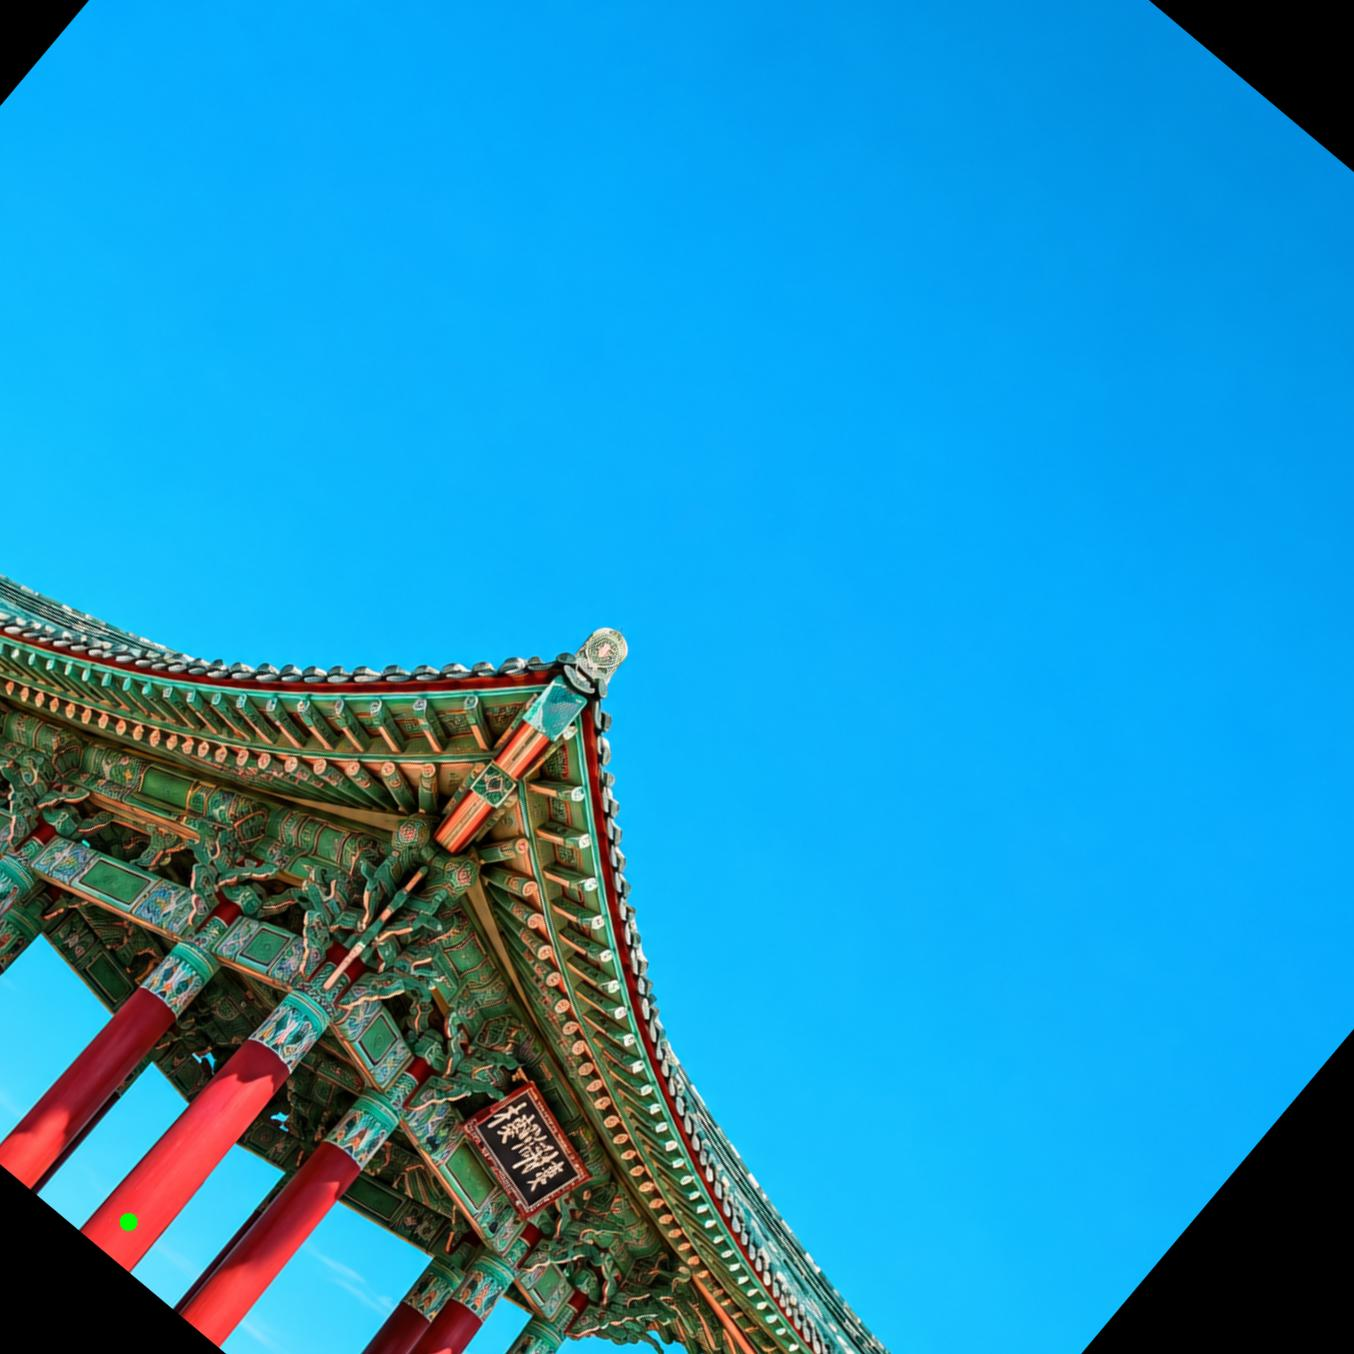

In [ ]:
# 이미지의 중심을 기준으로 시계방향 회전 후 확대/축소
degree = 40
scale = 1.3

M_scale = cv2.getRotationMatrix2D(center, -degree, scale)
centerInvRotatedScaled = cv2.warpAffine(image, M_scale,(width+100,height+100))

cv2_imshow(centerInvRotatedScaled)

**01.5 반전변환(Reflection Transformation)**

1. 어파인 매트릭스를 사용한 반전
  
  ```
  cv.warpAffine(srcImage,matrix,(width,height))
  ```

  반전변환의 Affine Matrix:

$$
\mathbf{M_{y-axis}}
=
\begin{bmatrix}
    1   &0    &0 \\
    0   &-1   &0  \\
\end{bmatrix}
$$

<br>

$$
\mathbf{M_{x-axis}}
=
\begin{bmatrix}
    -1   &0    &0 \\
    0   &1   &0  \\
\end{bmatrix}
$$

<br>

$$
\mathbf{M_{origin}}
=
\begin{bmatrix}
    -1   &0    &0 \\
    0   &-1   &0  \\
\end{bmatrix}
$$



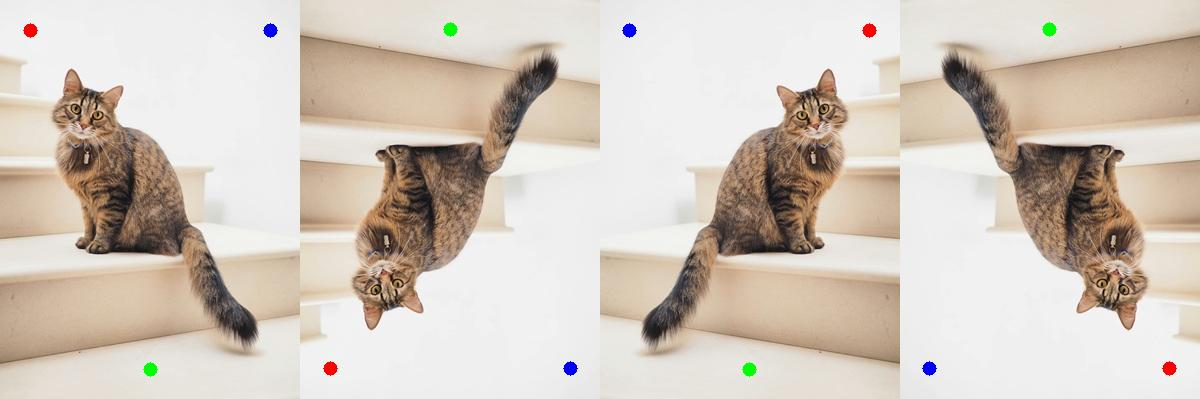

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/cat300x400.jpg')
(height, width, channel) = image.shape[:]

# 이미지에 점 세 개 표시
cv2.circle(image, (30,30), 7, (0,0,255), -1)
cv2.circle(image, (width//2,height-30), 7, (0,255,0), -1)
cv2.circle(image, (width-30,30), 7, (255,0,0), -1)

# x축 반전변환 넘파이 매트릭스
# [[1, 0, translateX],
# [0, -1, translateY]]

# y축 반전변환 넘파이 매트릭스
# [[-1, 0, translateX],
# [0, 1, translateY]]

# 원점(origin) 반전변환 넘파이 매트릭스
# [[-1, 0, translateX],
# [0, -1, translateY]]

M = np.float32([[1, 0, 0],
                [0, 1, 0]])
notReflected = cv2.warpAffine(image, M, (width,height))

M = np.float32([[1, 0, 0],
                [0, -1, height-1]])
xReflected = cv2.warpAffine(image, M, (width,height))

M = np.float32([[-1, 0, width-1],
                [0, 1, 0]])
yReflected = cv2.warpAffine(image, M, (width,height))

M = np.float32([[-1, 0, width-1],
                [0, -1, height-1]])
originReflected = cv2.warpAffine(image, M, (width,height))

reflection_frame = cv2.hconcat([notReflected, xReflected, yReflected, originReflected])
cv2_imshow(reflection_frame)

2. flip 함수를 이용한 반전
  ```
  cv2.flip(image, reflection)
  ```
  Parameter:
  - image: 반전변환 할 이미지
  - reflection
    - 0:  x축으로 뒤집기 (vertical flipping)
    - 1:  y축으로 뒤집기 (horizontal flipping)
    - -1: x축과 y축으로 뒤집기 (vertical and horizontal flipping)


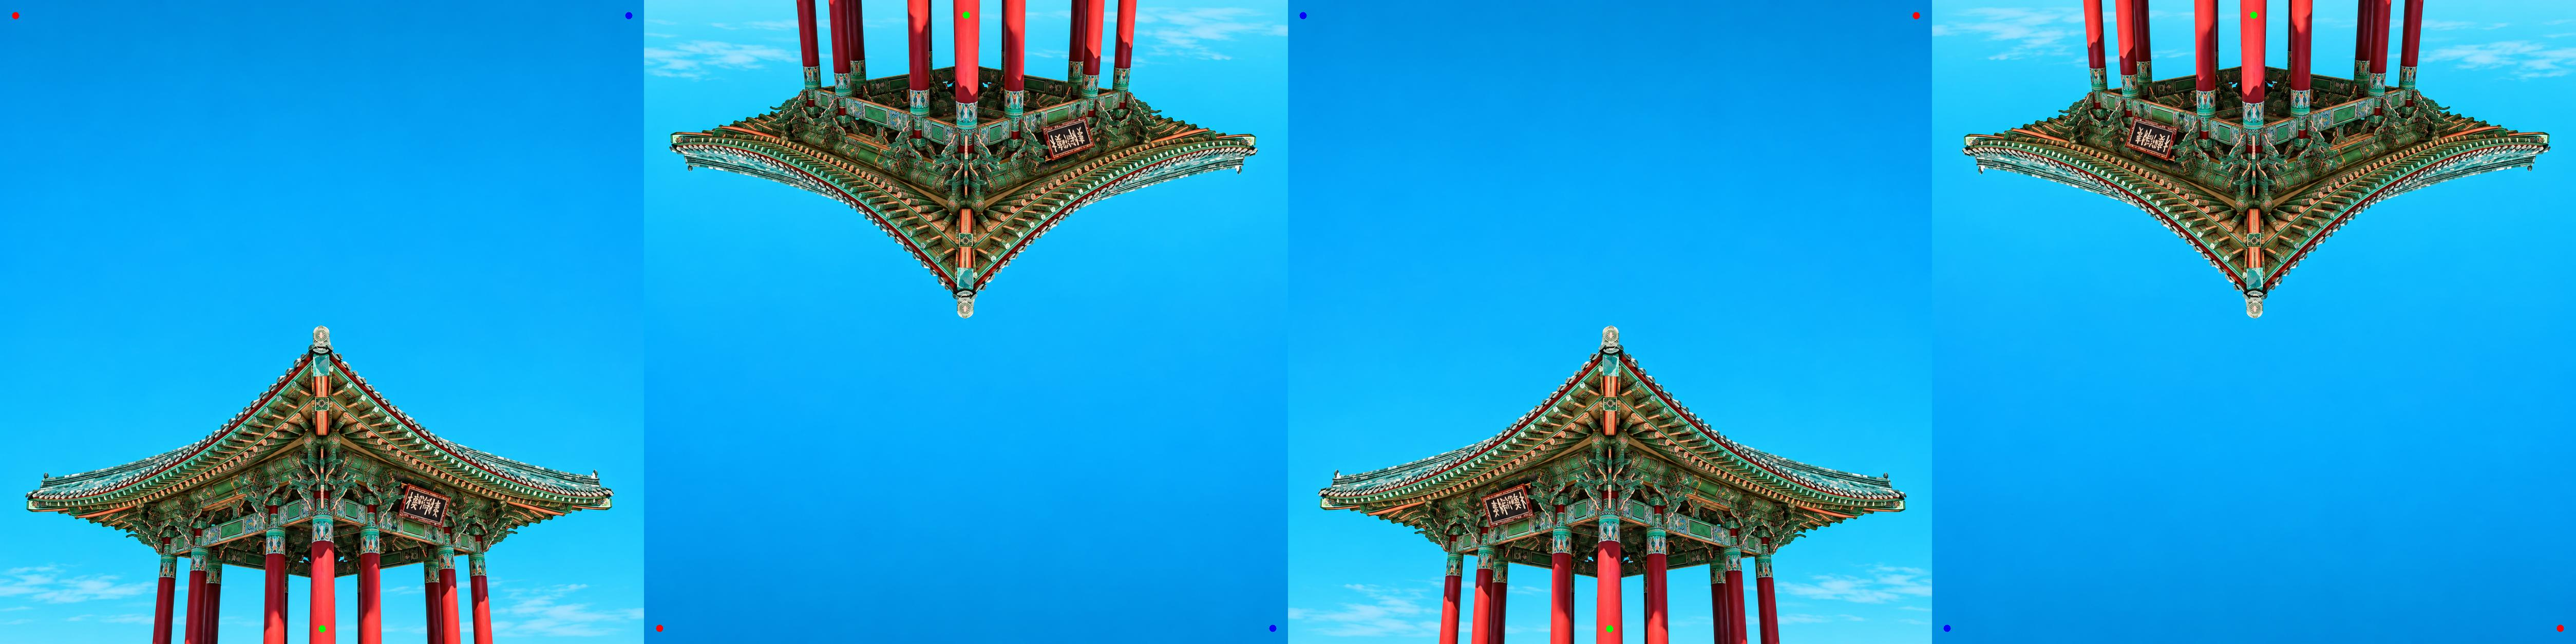

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/building300x200.jpg')
(height, width, channel) = image.shape[:]

# 이미지에 점 세 개 표시
cv2.circle(image, (30,30), 7, (0,0,255), -1)
cv2.circle(image, (width//2,height-30), 7, (0,255,0), -1)
cv2.circle(image, (width-30,30), 7, (255,0,0), -1)

flipVertical = cv2.flip(image, 0)
flipHorizontal = cv2.flip(image, 1)
flipBoth = cv2.flip(image, -1)

shift_frame = cv2.hconcat([image,flipVertical,flipHorizontal,flipBoth])
cv2_imshow(shift_frame)

**01.6 변환함수 만들어 활용하기**

In [ ]:
def translate(image, x, y):
	M = np.float32([[1, 0, x], [0, 1, y]])
	shifted = cv2.warpAffine(image, M, (image.shape[1], image.shape[0]))
	return shifted

def rotate(image, angle, center = None, scale = 1.0):
	(h, w) = image.shape[:2]
	if center is None:
		center = (w // 2, h // 2)

	M = cv2.getRotationMatrix2D(center, angle, scale)
	rotated = cv2.warpAffine(image, M, (w, h))
	return rotated

def resize(image, width = None, height = None, inter = cv2.INTER_AREA):
	# initialize the dimensions of the image to be resized and
	dim = None
	(h, w) = image.shape[:2]

	if width is None and height is None:
		return image
	if width is None or height is None:
		if width is None:
			r = height / float(h)
			dim = (int(w * r), height)
		else:
			r = width / float(w)
			dim = (width, int(h * r))
	else:
		dim = (width, height)

	resized = cv2.resize(image, dim, interpolation = inter)
	return resized


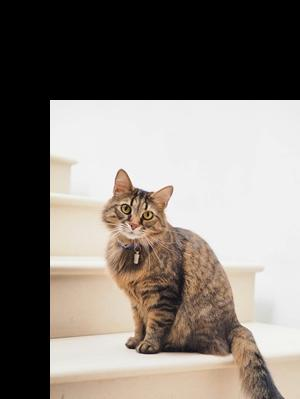

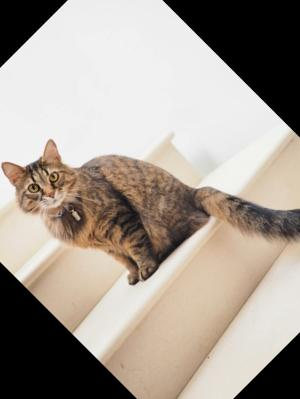

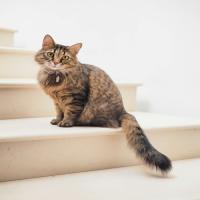

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/cat300x400.jpg')

cv2_imshow(translate(image,50,100))
cv2_imshow(rotate(image,45))
cv2_imshow(resize(image,200,200))

**01.7 세 개의 점으로 어파인 변환(Affine Transformation) 매트릭스 구하기**

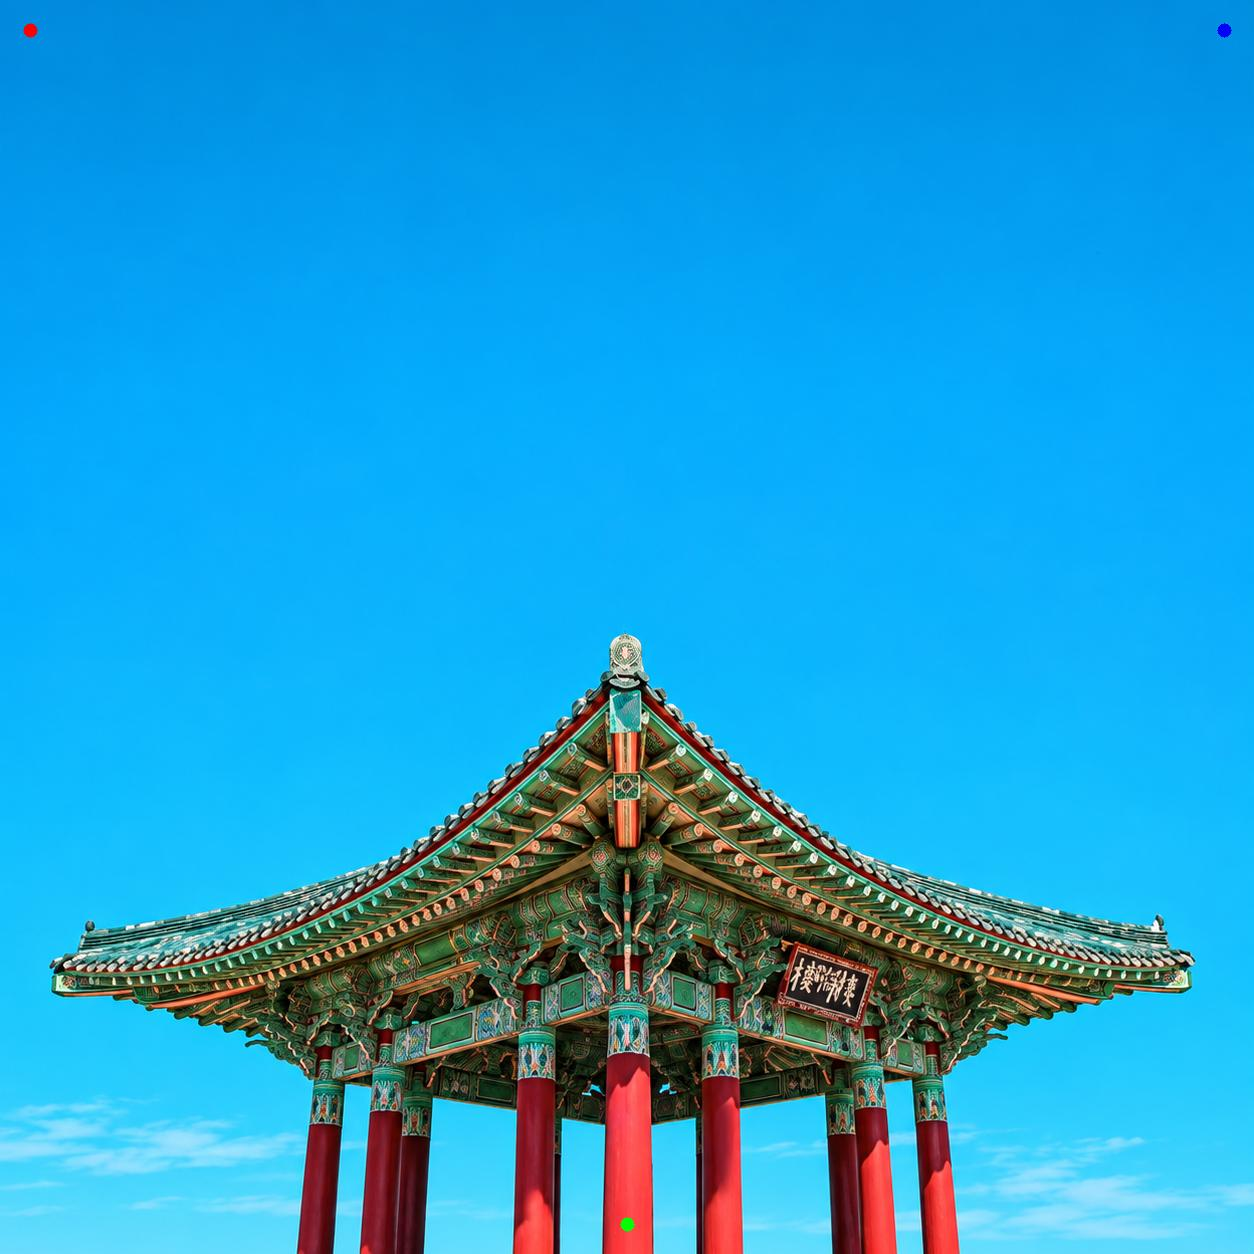

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/building300x200.jpg')
(height, width, channel) = image.shape[:]


# 이미지에 점 세 개 표시
cv2.circle(image, (30,30), 7, (0,0,255), -1)
cv2.circle(image, (width//2,height-30), 7, (0,255,0), -1)
cv2.circle(image, (width-30,30), 7, (255,0,0), -1)

cv2_imshow(image)

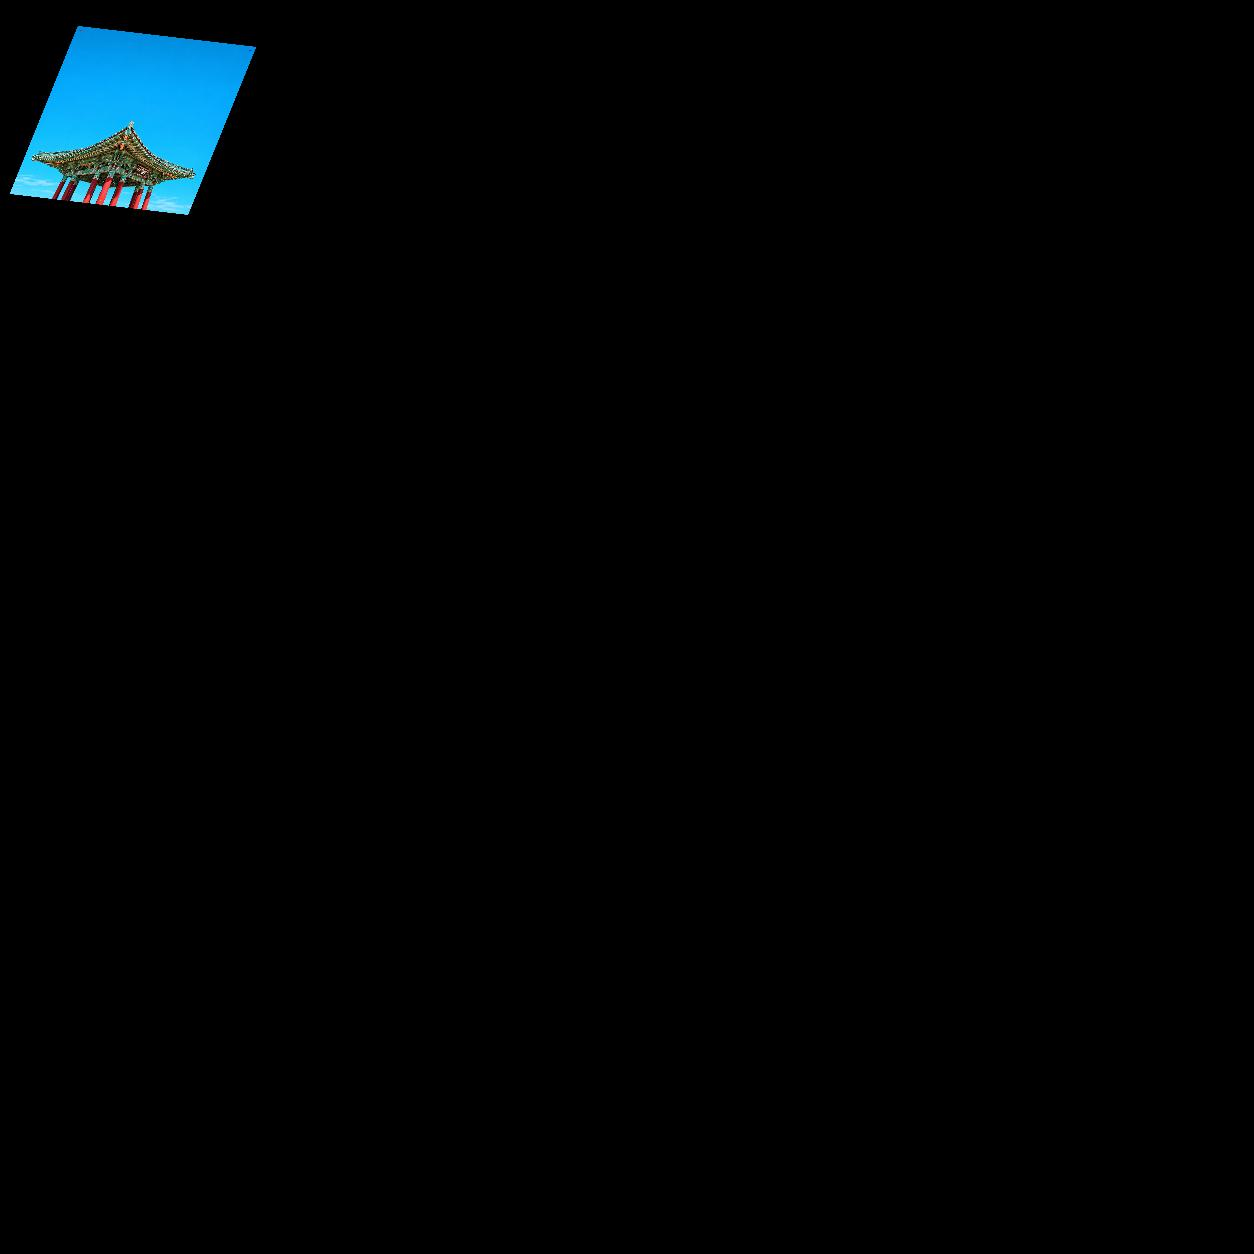

[[ 1.42378559e-01 -5.44388610e-02  7.73618090e+01]
 [ 1.67504188e-02  1.34003350e-01  2.54773869e+01]]


In [ ]:
#변환전 세 점 위치와 변환 후 세 점 위치
pointsBefore = np.float32([[30,30], [width//2,height-30], [width-30,30]])
pointsAfter = np.float32([[80,30], [100,200], [250,50]])

#어파인 매트릭스 구하기
M = cv2.getAffineTransform(pointsBefore, pointsAfter)
imageResult = cv2.warpAffine(image, M, (width, height))

cv2_imshow(imageResult)
print(M)

**01.8 삼각형 ROI구간을 어파인 변환으로 변환하기**

삼각형 활용 참고예시
- [Face Morphing1](https://inst.eecs.berkeley.edu/~cs194-26/fa18/upload/files/proj4/cs194-26-aaj/)
- [Face Morphing2](https://inst.eecs.berkeley.edu/~cs194-26/fa17/upload/files/proj4/cs194-26-abw/)


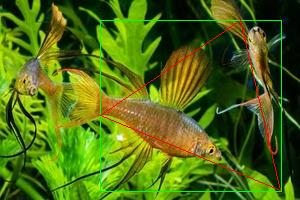

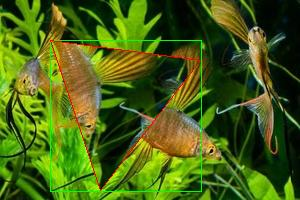

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/fish300x200.jpg')
(height, width, channel) = image.shape[:]

image2 = image.copy()
draw = image.copy()

# 변환 전과 후의 삼각형 좌표
x,y=70,10
pointsBefore = np.float32([[100,115], [240,20], [280,190]])
#pointsAfter = np.float32([[100-x,115-y], [240-x,20-y], [280-x,190-y]])
pointsAfter = np.float32([[50,40], [200,60], [100,190]])


# 각 삼각형을 완전히 감싸는 사각형 좌표 구하기
x1,y1,w1,h1 = cv2.boundingRect(pointsBefore)
x2,y2,w2,h2 = cv2.boundingRect(pointsAfter)

# 사각형을 이용한 관심영역 설정
roi1 = image[y1:y1+h1, x1:x1+w1]
roi2 = image2[y2:y2+h2, x2:x2+w2]

# 관심영역을 기준으로 좌표 계산
offset1 = np.zeros((3,2), dtype=np.float32)
offset2 = np.zeros((3,2), dtype=np.float32)
for i in range(3):
    offset1[i][0], offset1[i][1] = pointsBefore[i][0]-x1, pointsBefore[i][1]-y1
    offset2[i][0], offset2[i][1] = pointsAfter[i][0]-x2, pointsAfter[i][1]-y2

# 관심 영역을 주어진 삼각형 좌표로 어파인 변환
mtrx = cv2.getAffineTransform(offset1, offset2)
warped = cv2.warpAffine( roi1, mtrx, (w2, h2), None, cv2.INTER_LINEAR, cv2.BORDER_REFLECT_101)

# 어파인 변환 후 삼각형만 골라 내기 위한 마스크 생성
mask = np.zeros((h2, w2), dtype = np.uint8)
cv2.fillConvexPoly(mask, np.int32(offset2), (255))
inverse_mask = cv2.bitwise_not(mask)

# 삼각형 영역만 마스킹해서 합성
warped_masked = cv2.bitwise_and(warped, warped, mask=mask)
roi2_masked = cv2.bitwise_and(roi2, roi2, mask=inverse_mask)
roi2_masked = roi2_masked + warped_masked
image2[y2:y2+h2, x2:x2+w2] = roi2_masked

# 관심 영역과 삼각형 추가 후 그림 출력
cv2.rectangle(draw, (x1, y1), (x1+w1, y1+h1), (0,255,0), 1)
cv2.polylines(draw, [pointsBefore.astype(np.int32)], True, (0,0,255), 1)
cv2_imshow(draw)

cv2.rectangle(image2, (x2, y2), (x2+w2, y2+h2), (0,255,0), 1)
cv2.polylines(image2, [pointsAfter.astype(np.int32)], True, (0,0,255), 1)
cv2_imshow(image2)

##02 이미지의 원근변환 (Perspective Transformation)

**원근변환 (Perspective Transformation)**
- 어파인보다 자유도가 높음
- 원근변환은 직사각형 형태의 영상을 임의의 볼록 사각형 형태로 변경할 수 있음
- 변환 전 이미지와 변환 후 이미지의 네 점의 이동 관계에 의해 결정
- **Perspective Transformation Matrix**: 어파인 변환은 두 이미지의 관계를 정의한 3×3 매트릭스로 설명할 수 있음
- 매트릭스는 numpy.float32 실수형 자료형을 사용

**02.1 네 개의 점으로 원근변환(Perspective Transformation) 매트릭스 구하기**


```
 cv2.getPerspectiveTransform(pointsBefore,pointsAfter)
```
parameters:
- pointsBefore: 변환 전 네 점의 위치
- pointsAfter: 변환 후 네 점의 위치


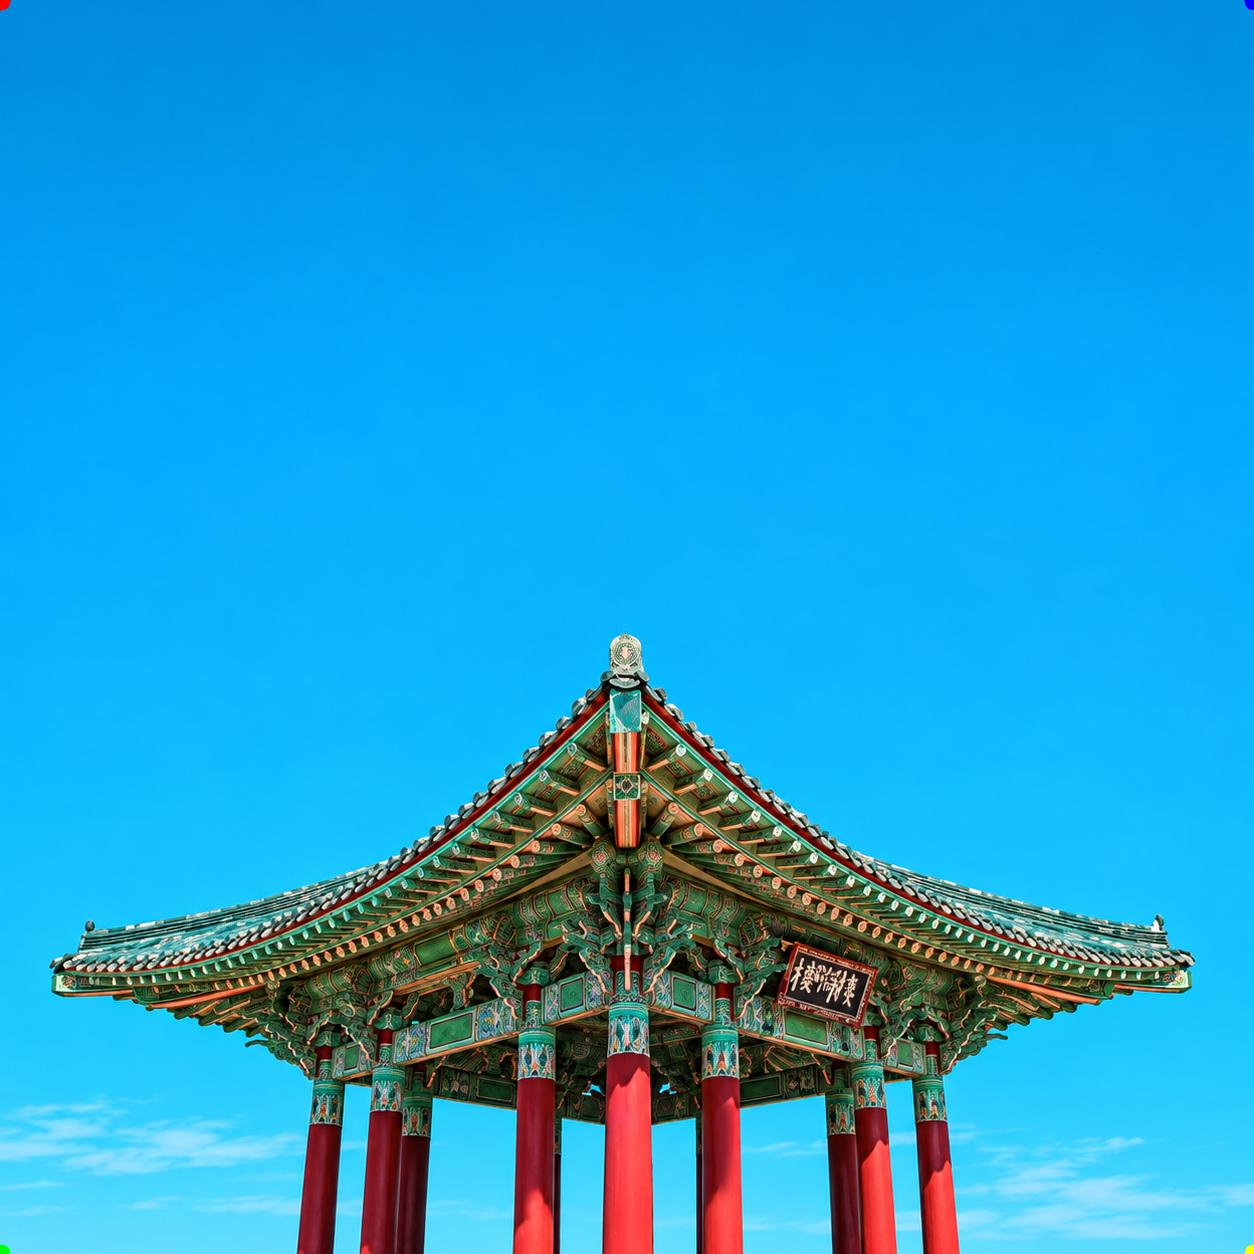

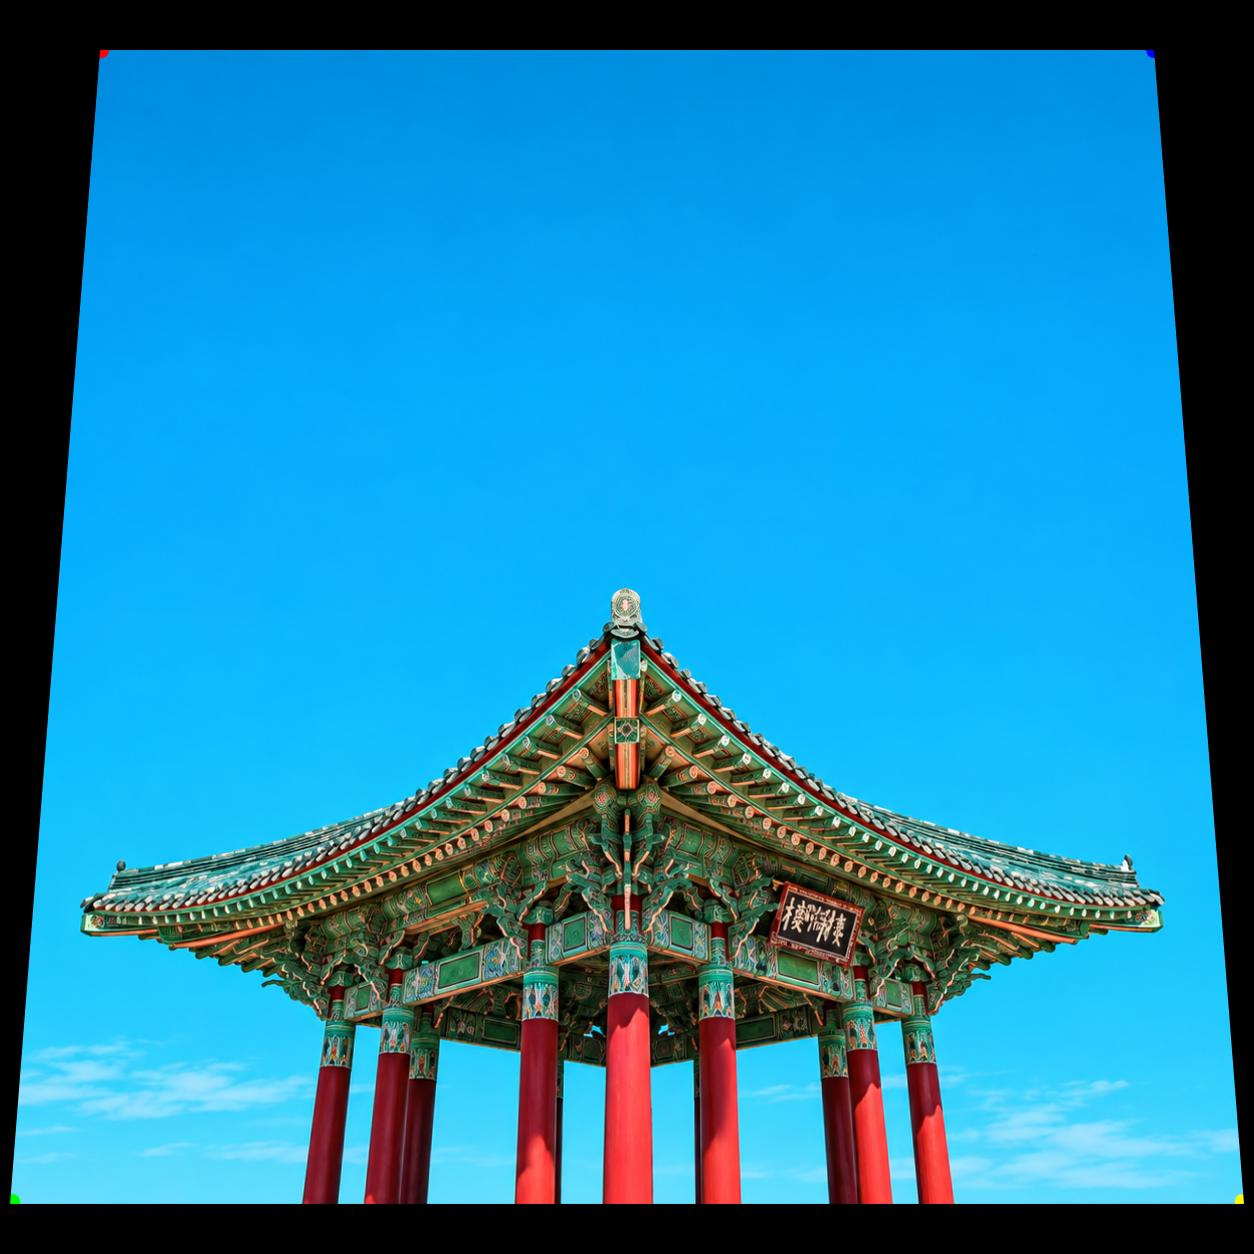

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/building300x200.jpg')
(height, width, channel) = image.shape[:]

# 이미지에 점 네 개 표시
cv2.circle(image, (0,0), 10, (0,0,255), -1)
cv2.circle(image, (0,height), 10, (0,255,0), -1)
cv2.circle(image, (width,0), 10, (255,0,0), -1)
cv2.circle(image, (width,height), 10, (0,255,255), -1)


#변환 전 네 점 위치와 변환 후 네 점 위치
pointsBefore = np.float32([[0,0], [0,height], [width, 0], [width,height]])
pointsAfter = np.float32([[100,50], [10,height-50], [width-100, 50], [width-10,height-50]])

#원근변환 행렬 구하기
M = cv2.getPerspectiveTransform(pointsBefore,pointsAfter)
#원근변환 적용
result = cv2.warpPerspective(image, M, (width, height))

cv2_imshow(image)
cv2_imshow(result)

**02.2 원근변환으로 ROI 정사각형 이미지 추출하기**

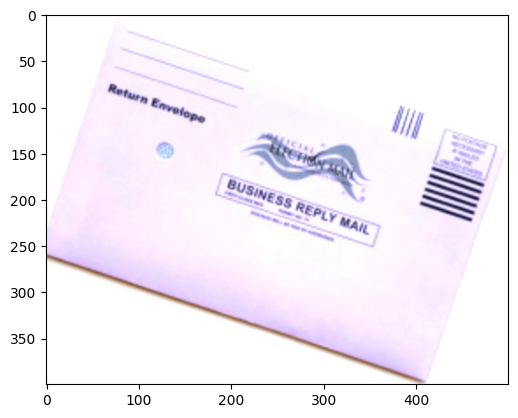

In [ ]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow
from matplotlib import pyplot as plt
import matplotlib.image as mpimg

image = mpimg.imread('/content/drive/MyDrive/Colab Notebooks/photos/envelope500x400.jpg')
(height, width, channel) = image.shape[:]

imgplot = plt.imshow(image)
plt.show()

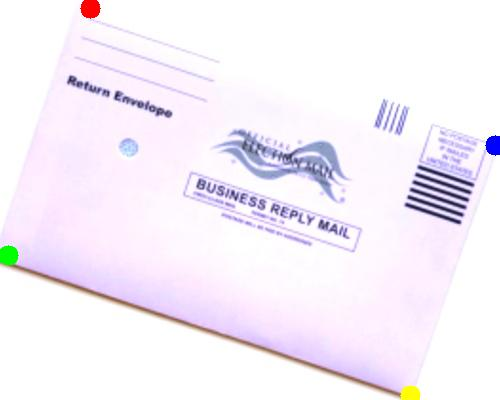

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np

image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/envelope500x400.jpg')
(height, width, channel) = image.shape[:]

#네 점의 좌표를 정한다.
P1 = (90,8)
P2 = (8,255)
P3 = (410,395)
P4 = (495,145)

# 이미지에 점 네 개 표시
cv2.circle(image, P1, 10, (0,0,255), -1)
cv2.circle(image, P2, 10, (0,255,0), -1)
cv2.circle(image, P3, 10, (0,255,255), -1)
cv2.circle(image, P4, 10, (255,0,0), -1)

#원본 이미지 출력
cv2_imshow(image)

[P1와 P4] 427 , [P2와 P3] 425
[P1와 P2] 260 , [P4와 P3] 264
envelope_width: 427 envelope_height: 264




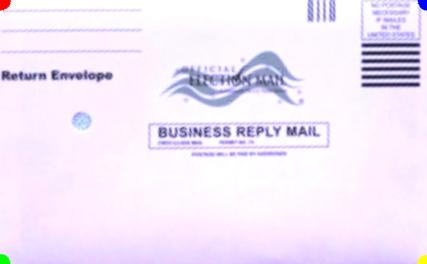

In [ ]:
# 두 점 사이의 거리 구하기
def distance(point1, point2):
  x1,y1 = point1
  x2,y2 = point2
  result = np.sqrt(np.power(x1 - x2, 2) + np.power(y1 - y2,2))
  return result

#ROI의 가로,세로 길이 구하기
envelope_width = max(int(distance(P1,P4)),int(distance(P2,P3)))
envelope_height = max(int(distance(P1,P2)), int(distance(P4,P3)))

print("[P1와 P4]",int(distance(P1,P4)),", [P2와 P3]",int(distance(P2,P3)))
print("[P1와 P2]",int(distance(P1,P2)),", [P4와 P3]",int(distance(P4,P3)))
print("envelope_width:",envelope_width,"envelope_height:",envelope_height)
print("\n")

#변환 전 네 점 위치와 변환 후 네 점 위치
pointsBefore = np.float32([P1, P2, P3, P4])
pointsAfter = np.float32([[0,0], [0,envelope_height], [envelope_width,envelope_height], [envelope_width,0]])


#원근변환 행렬 구하고 원근변환 적용
M = cv2.getPerspectiveTransform(pointsBefore,pointsAfter)
result = cv2.warpPerspective(image, M, (envelope_width, envelope_height))


#결과 이미지 출력
cv2_imshow(result)

##03 이미지의 리매핑 (Remapping)
- 리매핑은 이미지의 픽셀들을 다른 위치에 재배치하는 변환
  - remap() 함수를 사용해 결과 이미지의 좌표를 원본 이미지의 어느 좌표를 참조해서 가져올지 설정 후
  - 결과 이미지의 모든 픽셀 값을 셋팅해 결과 이미지를 출력
-  이미지를 직선이 아닌, 자유도 높은 곡선으로 표현 가능
  -  어파인 변환, 투시 변환 등, 다양한 변환을 리매핑으로 표현 가능


```
cv2.remap(srcImage, mapx, mapy, interpolation)
```
parameters:
- srcImage: 입력 이미지
- mapx, mapy: 결과 이미지의 (x, y) 좌표가 참조할 원본 이미지의 x좌표와 y좌표
  - 자료형이 np.float32인 numpy.ndarray
- interpolation: 보간법


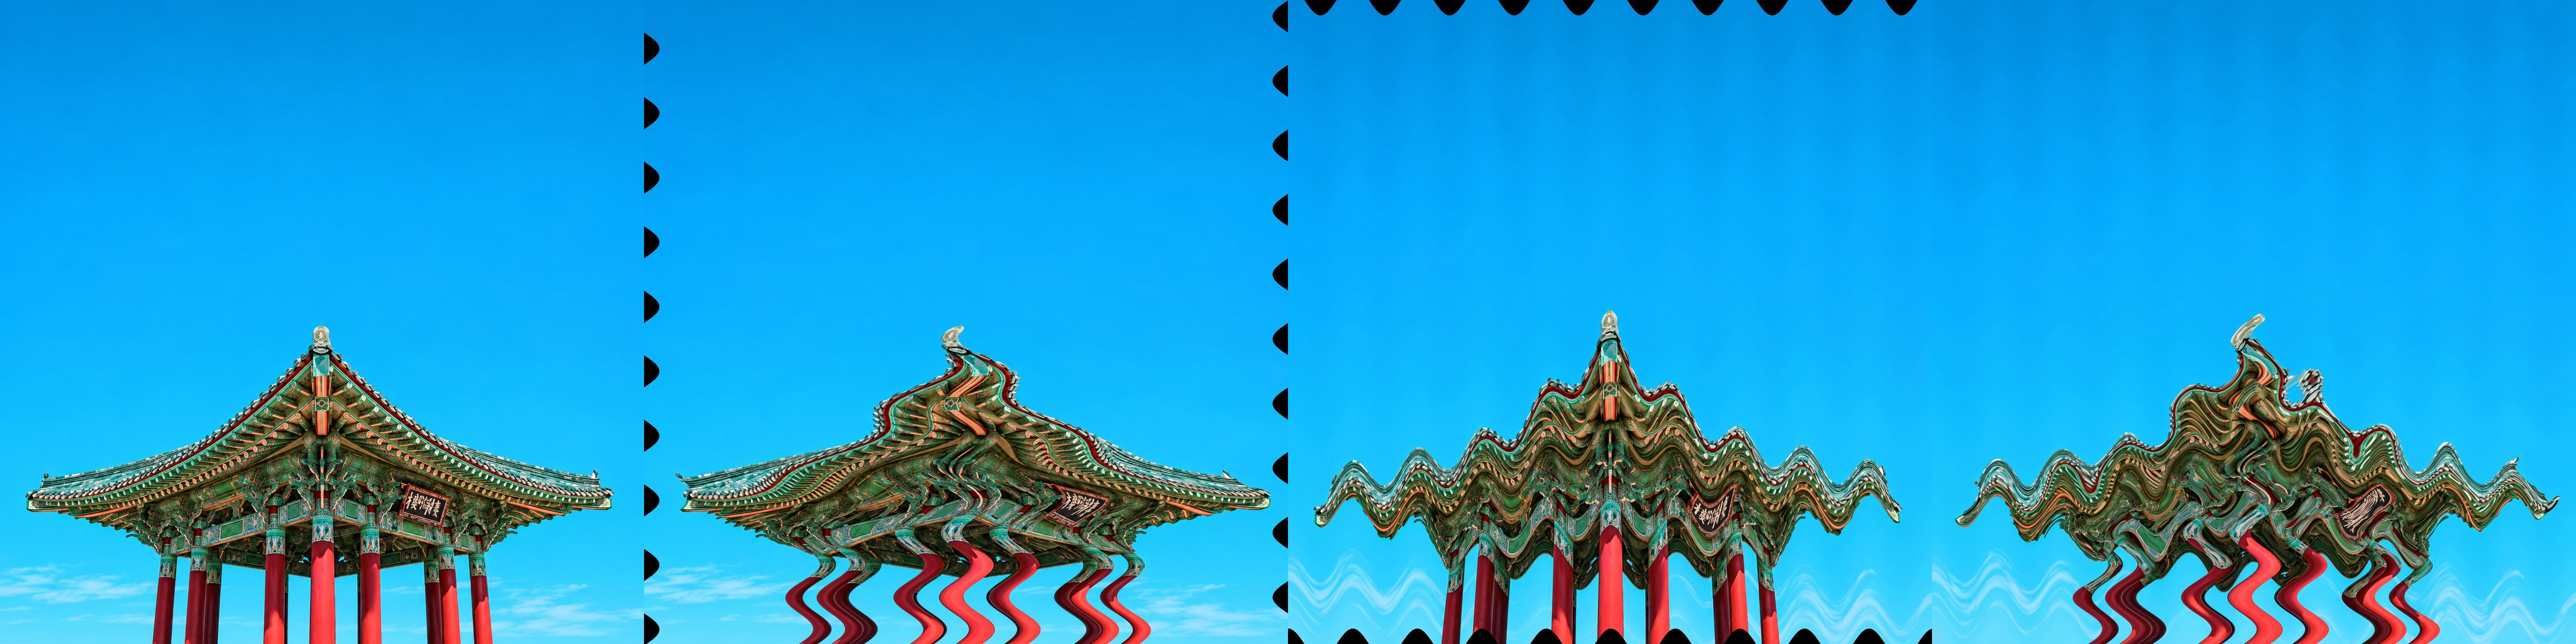

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

file_name = '/content/drive/MyDrive/Colab Notebooks/photos/building300x200.jpg'
image = cv2.imread(file_name)
(height, width, channel) = image.shape[:]

waveLength = 20      # 파장(wave length)
amplitude = 30    # 진폭(amplitude)

#np.indice는 행렬의 인덱스값의 x좌표값과 y좌표값을 각각 행렬의 형태로 변환
mapy, mapx = np.indices((height,width),dtype=np.float32)
#sin을 대입한 mapx와 cos을 대입한 mapy
sinx = mapx + amplitude * np.sin(mapy/waveLength)
cosy = mapy + amplitude * np.cos(mapx/waveLength)

#remap을 적용한 이미지
sinxImage = cv2.remap(image, sinx, mapy, cv2.INTER_LINEAR) # x축만 sin 곡선 적용
cosyImage = cv2.remap(image, mapx, cosy, cv2.INTER_LINEAR) # y축만 cos 곡선 적용
bothImage = cv2.remap(image, sinx, cosy, cv2.INTER_LINEAR, None, cv2.BORDER_REPLICATE)

remap_frame = cv2.hconcat([image,sinxImage,cosyImage,bothImage])
cv2_imshow(remap_frame)

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

file_name = '/content/drive/MyDrive/Colab Notebooks/photos/building300x200.jpg'
image = cv2.imread(file_name)
(height, width, channel) = image.shape[:]

exp = 1.5     # 볼록, 오목 지수 (오목 : 0.1 ~ 1, 볼록 : 1.1~)
scale = 1     # 변환 영역 크기 (0 ~ 1)

#np.indice는 행렬의 인덱스값의 x좌표값과 y좌표값을 각각 행렬의 형태로 변환
mapy, mapx = np.indices((height,width), dtype=np.float32)

# 좌상단 기준좌표에서 -1~1로 정규화된 중심점 기준 좌표로 변경
mapx = 2*mapx/(width-1)-1
mapy = 2*mapy/(height-1)-1

#직교좌표를 극 좌표로 변환
r, theta = cv2.cartToPolar(mapx, mapy)

#왜곡 영역만 중심확대/축소 지수 적용
r[r<scale] = r[r<scale]**exp

#극 좌표를 직교좌표로 변환
mapx, mapy = cv2.polarToCart(r, theta)

#중심점 기준에서 좌상단 기준으로 변경 ---⑦
mapx = ((mapx + 1)*width-1)/2
mapy = ((mapy + 1)*height-1)/2

#재매핑 변환
distorted = cv2.remap(image,mapx,mapy,cv2.INTER_LINEAR)

cv2_imshow(image)
cv2_imshow(distorted)


##04 카메라 렌즈의 왜곡

  - 핀홀 카메라를 쓴다면 왜곡이 없어야하지만 보통 렌즈를 사용해 이미지가 왜곡
  - 카메라 렌즈는 동그랗지만 이미지는 사각형이라서 렌즈 가장자리에 왜곡이 생김
  - 카메라에 시야각(FOV)이 넓은 광각렌즈나 초광각 렌즈를 사용하면 넓은 범위를 볼 수 있지만 상대적으로 영상 왜곡이 심해지는 문제가 생김

<br>

![img](https://programming.vip/images/doc/a1b2c02b82cddcc0920df8d71121b5dd.jpg)






<br><br>

**참고 링크 및 이미지 출처:**
- [카메라 왜곡보정 - 이론 및 실제](https://darkpgmr.tistory.com/31#menu1)
- [카메라 캘리브레이션 (camera calibration)](https://darkpgmr.tistory.com/32)
- [Radial Tangential Distortion](https://proto.readthedocs.io/en/latest/cv/radtan.html)
- [Camera Calibration](http://mesh.brown.edu/3DP-2018/calibration.html)
- [Programming VIP](https://programming.vip/docs/fusion-series-of-unmanned-sensors-camera-internal-reference-calibration.html)


**04.1 방사형 왜곡(Radial distortion)**
  - 방사왜곡은 볼록렌즈의 굴절률에 의해 생기며 영상의 왜곡 정도가 이미지의 중심에서 멀어질 수록 왜곡 정도가 달라짐
  ![img](https://proto.readthedocs.io/en/latest/_images/radial_distortion.png)
<img src="https://programming.vip/images/doc/ef95df55cbc2cef42e59f459e188340d.jpg" alt="drawing" height="300"/>


**04.2 접선 왜곡 (Tangential distortion)**
  - 카메라 제조/조립 과정에서 카메라 렌즈와 이미지센서(CCD,CMOS)의 수평이 맞지 않거나 또는 렌즈 자체의 centering이 맞지 않아서 발생하는 왜곡
  
    ![img](https://proto.readthedocs.io/en/latest/_images/tangential_distortion.png)

    <img src="https://programming.vip/images/doc/6b3d35d2b6383ee84ef81428c0b53217.jpg" alt="drawing" height="300"/>
   

**04.3 cv2.undistort()함수를 사용해 이미지 왜곡/보정**

<img src="https://programming.vip/images/doc/a97f361d9c9f147bd4e8b1780c25ad0b.jpg" alt="img" height="250"/>
<img src="https://programming.vip/images/doc/3d9272acdc2c814073427626394051a7.jpg" alt="img" height="250"/>


  ```
  cv2.undistort(srcImage, cameraMatrix, distortCoeffs)
  ```
  parameters:
  - srcImage: 입력이미지
  - cameraMatrix: 카메라 매트릭스; 카메라 마다 고유의 내부 파라미터가 존재
    - 카메라 렌즈의 중심점(optical centers) $c_x$, $c_y$
    - 초점 거리(focal length) $f_x$, $f_y$
    
      <img src="https://t1.daumcdn.net/cfile/tistory/22504A475344768E06" alt="img" height="100"/>


  $$
  \mathbf{CameraMatrix}
  =
  \begin{bmatrix}
      f_x  &0    &c_x \\
      0    &f_y  &c_y \\
      0    &0    &1   \\
  \end{bmatrix}
  $$

  - distortCoeffs: 왜곡계수 최소 4개, 혹은 5,8,12,14...
    <img src="https://opencv-python-tutroals.readthedocs.io/en/latest/_images/math/26ad926921974fb12443390fe4f8e91c9c2a9e38.png" alt="img" width="400"/>
    
    - 방사형 왜곡계수: k1, k2, (k3...)
    - 접선 왜곡계수: p1, p2  
    
<img src="https://programming.vip/images/doc/0f79ced7d99c8636a64dd191a44bdcc8.jpg" alt="img" height="250"/>
<br>
<img src="https://programming.vip/images/doc/a95987abd6330efc479ef80d5cf3e121.jpg" alt="img" height="100"/>
<img src="https://programming.vip/images/doc/2143c90fcda29a6740f33bdac5a8bef4.jpg" alt="img" height="100"/>
<br>


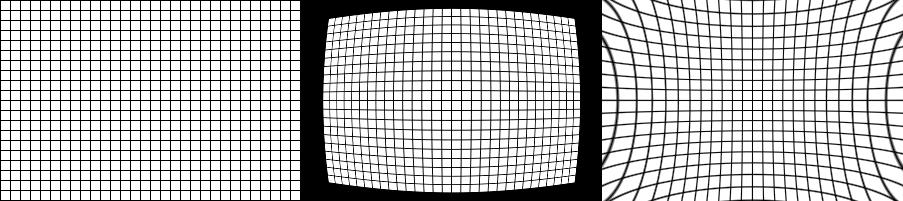

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

#격자 무늬 이미지 만들기
image = np.full((201,301,3), 255, np.uint8)
image[::10, :, :] = 0 #세로간격
image[:, ::10, :] = 0 #가로간격
(height, width, channel) = image.shape[:]

# 임의의 카메라 매트릭스 생성
fx, fy = 10, 10
cx, cy = width/2, height/2
cameraM = np.float32([[fx,  0,  cx],
                      [0,  fy,  cy],
                      [0,   0,   1]])

#왜곡 계수
distCoeff_barrel = np.float64([0.001, 0, 0, 0]) # 배럴 왜곡
distCoeff_pincushion = np.float64([-0.001, 0, 0, 0]) # 핀쿠션 왜곡


# 렌즈왜곡 구현
barrel = cv2.undistort(image,cameraM,distCoeff_barrel)
pincushion = cv2.undistort(image,cameraM,distCoeff_pincushion)

distortion_frame = cv2.hconcat([image,barrel,pincushion])
cv2_imshow(distortion_frame)

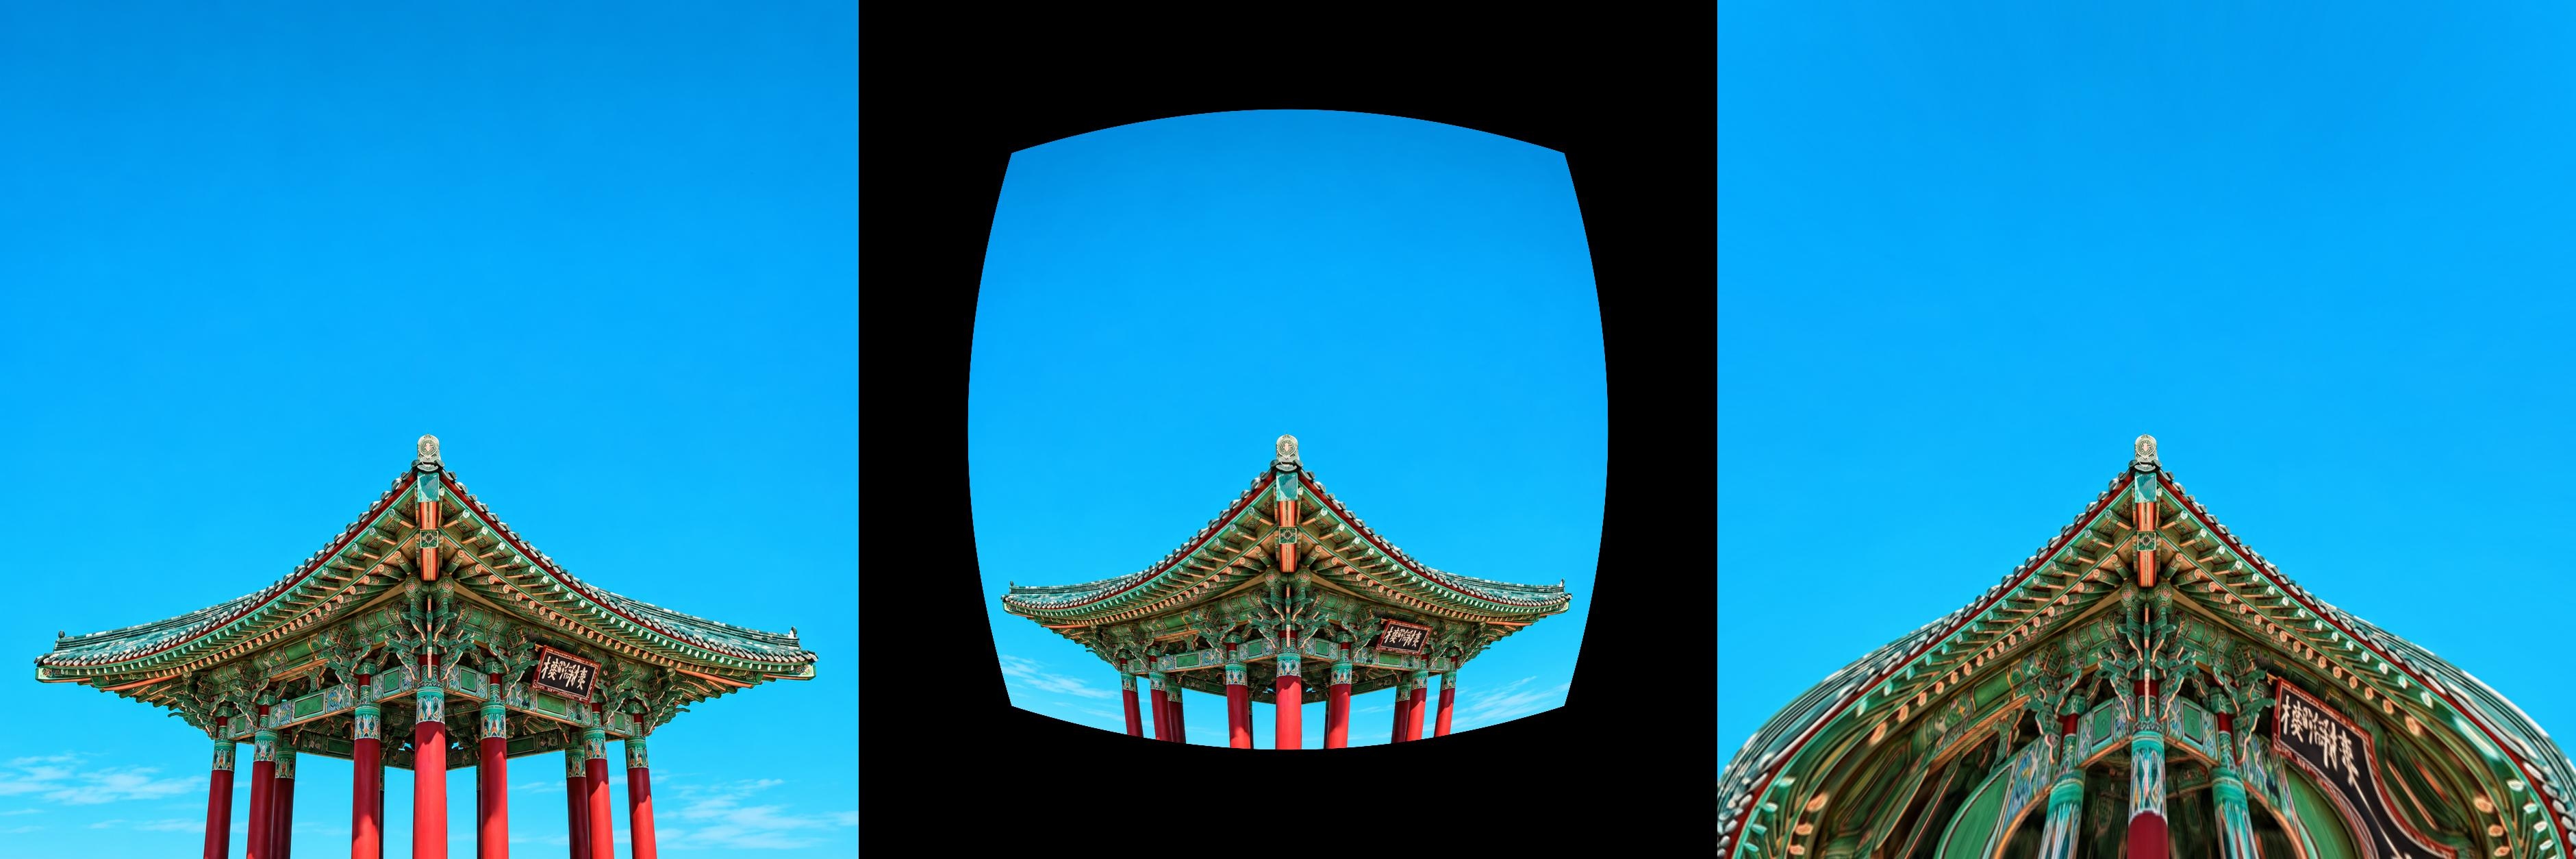

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

file_name = '/content/drive/MyDrive/Colab Notebooks/photos/building300x200.jpg'
image = cv2.imread(file_name)
(height, width, channel) = image.shape[:]

# 왜곡계수 설정
k1_b, k2_b, k3_b = 0.5, 0.2, 0.0     # 배럴 왜곡
k1_p, k2_p, k3_p = -0.3, 0.0, 0.0    # 핀쿠션 왜곡

# 매핑배열 생성
mapy, mapx = np.indices((height, width), dtype=np.float32)

# 중앙점 좌표로 -1~1 정규화 및 극좌표 변환
mapx = 2*mapx/(width-1)-1
mapy = 2*mapy/(height-1)-1
r, theta = cv2.cartToPolar(mapx, mapy)

# 방사왜곡 변형연산
ru_b = r*(1+k1_b*(r**2) + k2_b*(r**4) + k3_b*(r**6)) # 배럴 왜곡
ru_p = r*(1+k1_p*(r**2) + k2_p*(r**4) + k3_p*(r**6)) # 핀쿠션 왜곡

# 직교좌표 및 좌상단 기준으로 복원 후 배럴 왜곡 리매핑
mapx_b, mapy_b = cv2.polarToCart(ru_b, theta)
mapx_b = ((mapx_b + 1)*width-1)/2
mapy_b = ((mapy_b + 1)*height-1)/2
distored_b = cv2.remap(image,mapx_b,mapy_b,cv2.INTER_LINEAR)

# 직교좌표 및 좌상단 기준으로 복원 후 핀쿠션 왜곡 리매핑
mapx_p, mapy_p = cv2.polarToCart(ru_p, theta)
mapx_p = ((mapx_p + 1)*width-1)/2
mapy_p = ((mapy_p + 1)*height-1)/2
distored_p = cv2.remap(image,mapx_p,mapy_p,cv2.INTER_LINEAR)


distortion_frame = cv2.hconcat([image,distored_b,distored_p])
cv2_imshow(distortion_frame)

**04.4 카메라 캘리브레이션(Camera Calibration)**


- 3차원인 세상을 2차원인 이미지로 변환하려면 3차원의 점들이 이미지 상에서 어디에 맺히는지는 기하학적으로 변환해야 함
  
  ![img](https://t1.daumcdn.net/cfile/tistory/995410365E9F957133)
- 이미지의 형상을 결정하는 것은 찍을 당시의 카메라의 위치 및 방향과 사용된 렌즈도 중요하지만 렌즈와 이미지 센서와의 거리, 렌즈와 이미지 센서가 이루는 각 등 **카메라 내부의 물리적인 설계요소**에 의해서 크게 영향
- 3차원 점들이 영상에 투영된 위치를 구하거나 역으로 영상좌표로부터 3차원 공간좌표를 복원할 때에는 이러한 내부 요인을 제거해야만 정확한 계산이 가능
- **카메라 캘리브레이션:** 내부 요인의 파라미터 값을 구하는 과정

  - 코너와 점이 명확하고 직선 2D 평면이 명확하게 보여서 체스판/체커보드를 주로 사용
  <img src="https://raw.githubusercontent.com/opencv/opencv/master/doc/pattern.png" alt="drawing" height="200"/>

  - [체커보드 이미지](https://github.com/opencv/opencv/blob/master/doc/pattern.png)
  - [OpenCV 캘리브레이션 패턴 반들기](https://docs.opencv.org/master/da/d0d/tutorial_camera_calibration_pattern.html)


In [ ]:
#구글 드라이브 마운트 하기
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


Camera matrix :
[[1.15753287e+03 0.00000000e+00 6.75394657e+02]
 [0.00000000e+00 1.15190275e+03 3.86733608e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
Distortion matrix:
[[-0.26710721  0.10326603 -0.00087918  0.00080756 -0.19606092]]


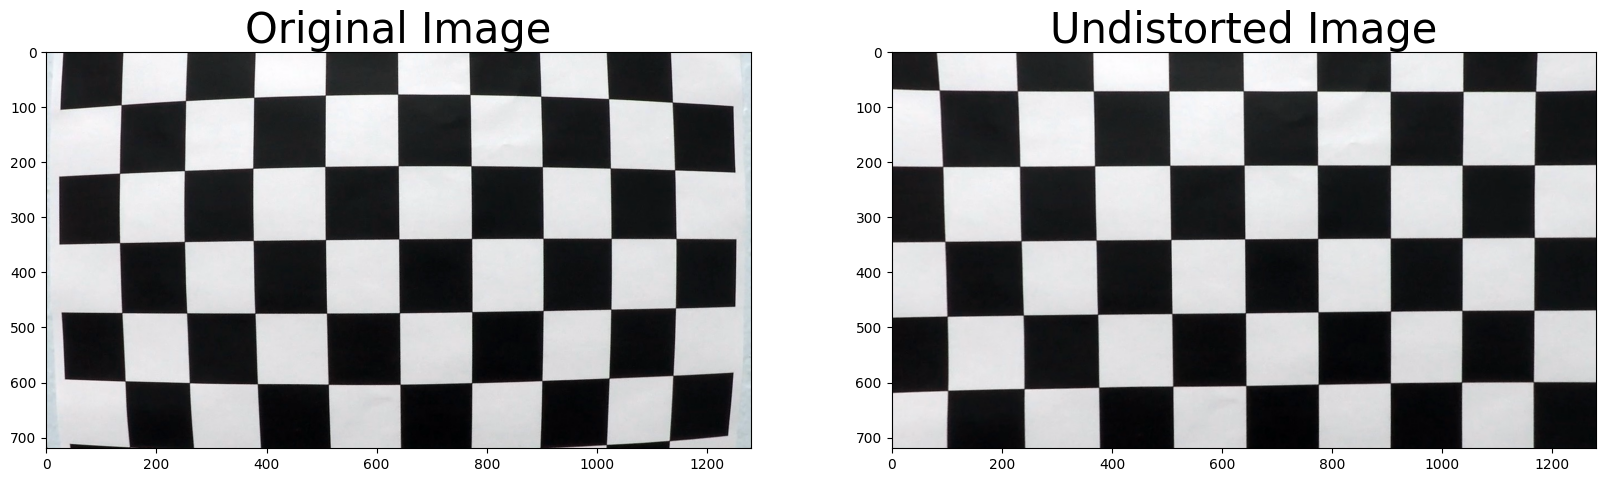

In [ ]:
#출처: https://programming.vip/docs/fusion-series-of-unmanned-sensors-camera-internal-reference-calibration.html
#캘리브레이션 체커보드 이미지 출처: https://github.com/godloveliang/Advanced-Lane-Finding/tree/master/camera_cal

import numpy as np
import cv2
import glob
import matplotlib.pyplot as plt
import matplotlib.image as mpimg


# prepare object points, like (0,0,0), (1,0,0), (2,0,0) ....,(6,5,0)
#Non-distorted chessboard corners
objp = np.zeros((6*9,3), np.float32)
objp[:,:2] = np.mgrid[0:9, 0:6].T.reshape(-1,2)

# Arrays to store object points and image points from all the images.
objpoints = [] # 3d points in real world space
imgpoints = [] # 2d points in image plane.

# Make a list of calibration images
#Import a set of checkerboard photos from different angles and distances
images = glob.glob('/content/drive/MyDrive/Colab Notebooks/photos/*.jpg')

# Step through the list and search for chessboard corners
#Find the corner, and then put in objpoints, imgpoints
for idx, fname in enumerate(images):
    img = cv2.imread(fname)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Find the chessboard corners
    ret, corners = cv2.findChessboardCorners(gray, (9,6), None)

    # If found, add object points, image points
    if ret == True:
        objpoints.append(objp)
        imgpoints.append(corners)


# Test undistortion on an image
img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/calibration1.jpg')
img_size = (img.shape[1], img.shape[0])

# Do camera calibration given object points and image points
# Calculating Distortion Coefficient
# mtx:3-to 2-dimensional image plane projection matrix, dist: distortion wash matrix [k1, k2, p1, p2, k3].
ret, mtx, dist, rvecs, tvecs = cv2.calibrateCamera(objpoints, imgpoints, img_size,None,None)

# De-distortion the picture
dst = cv2.undistort(img, mtx, dist, None, mtx)

print("Camera matrix :")
print(mtx)
print("Distortion matrix:")
print(dist)

# Visualize undistortion

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20,10))
ax1.set_title('Original Image', fontsize=30)
ax1.imshow(img)
ax2.set_title('Undistorted Image', fontsize=30)
ax2.imshow(dst)
plt.show()

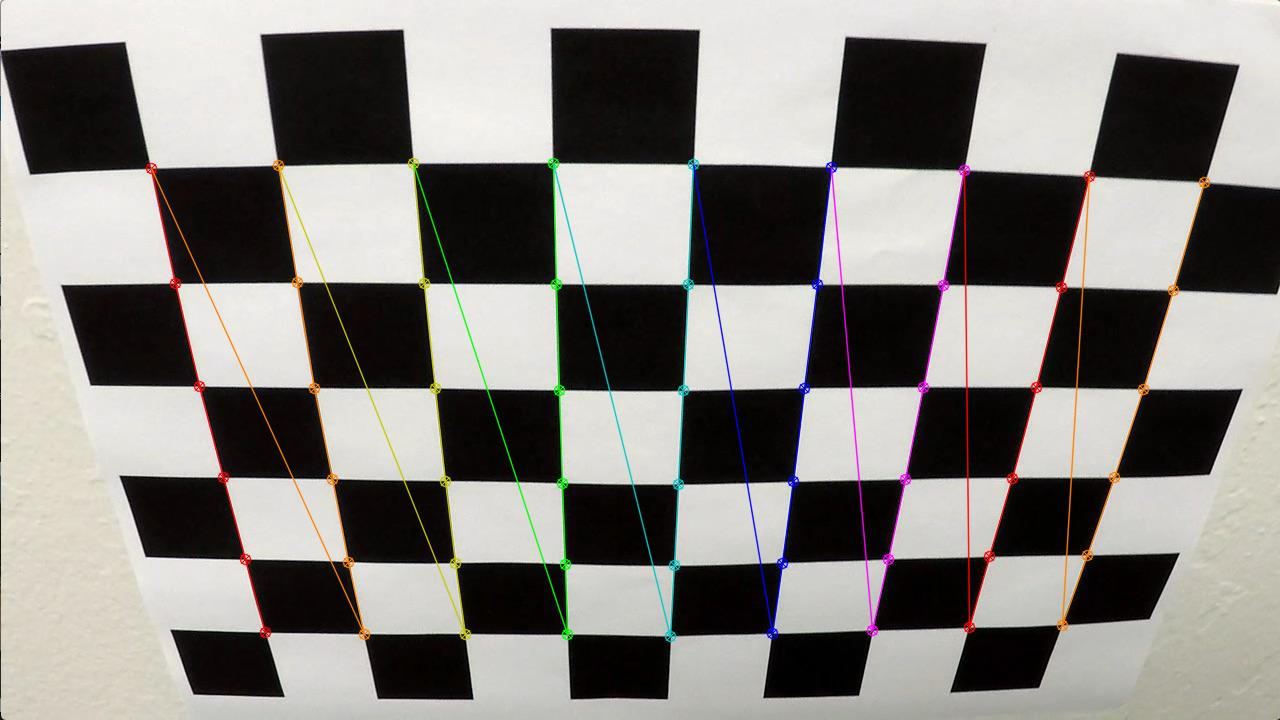

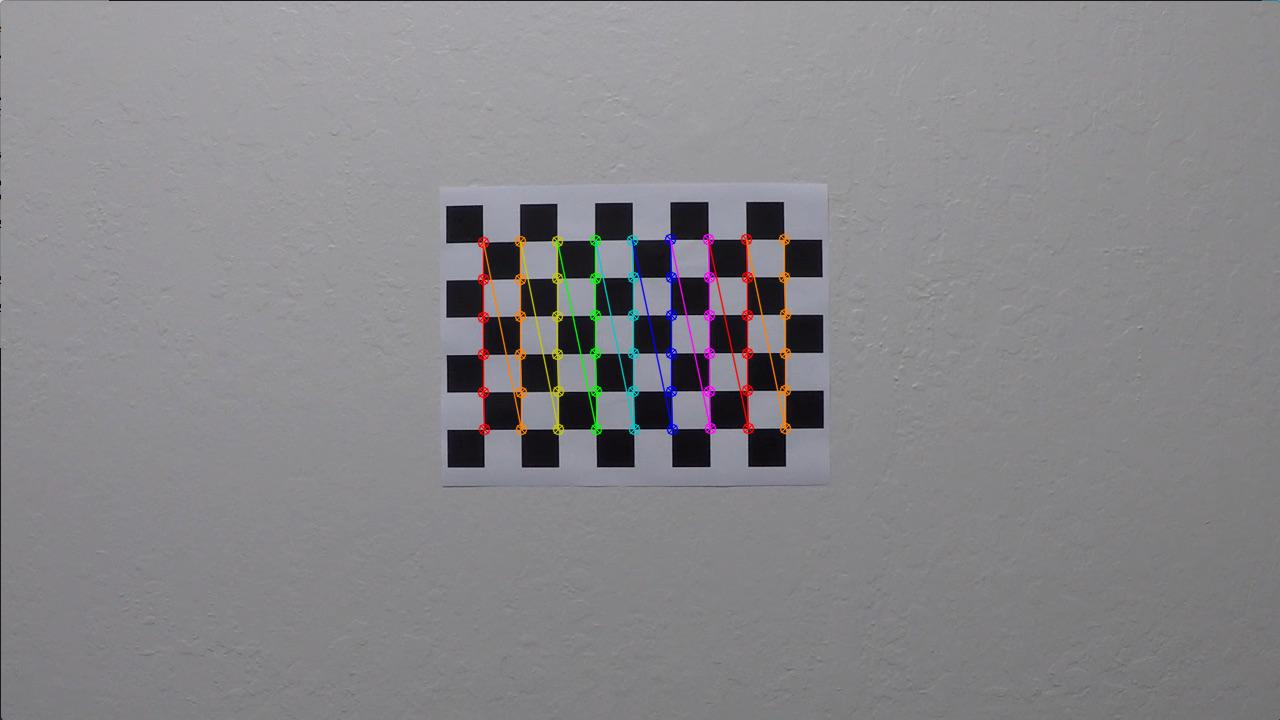

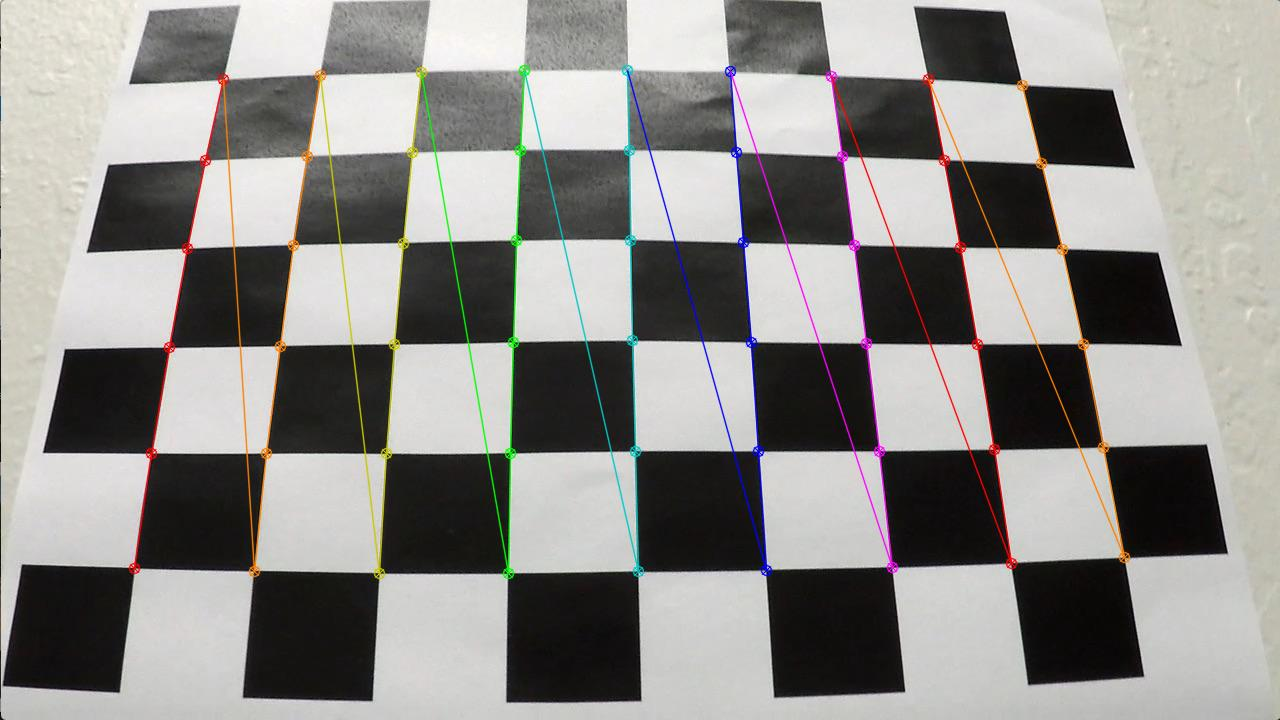

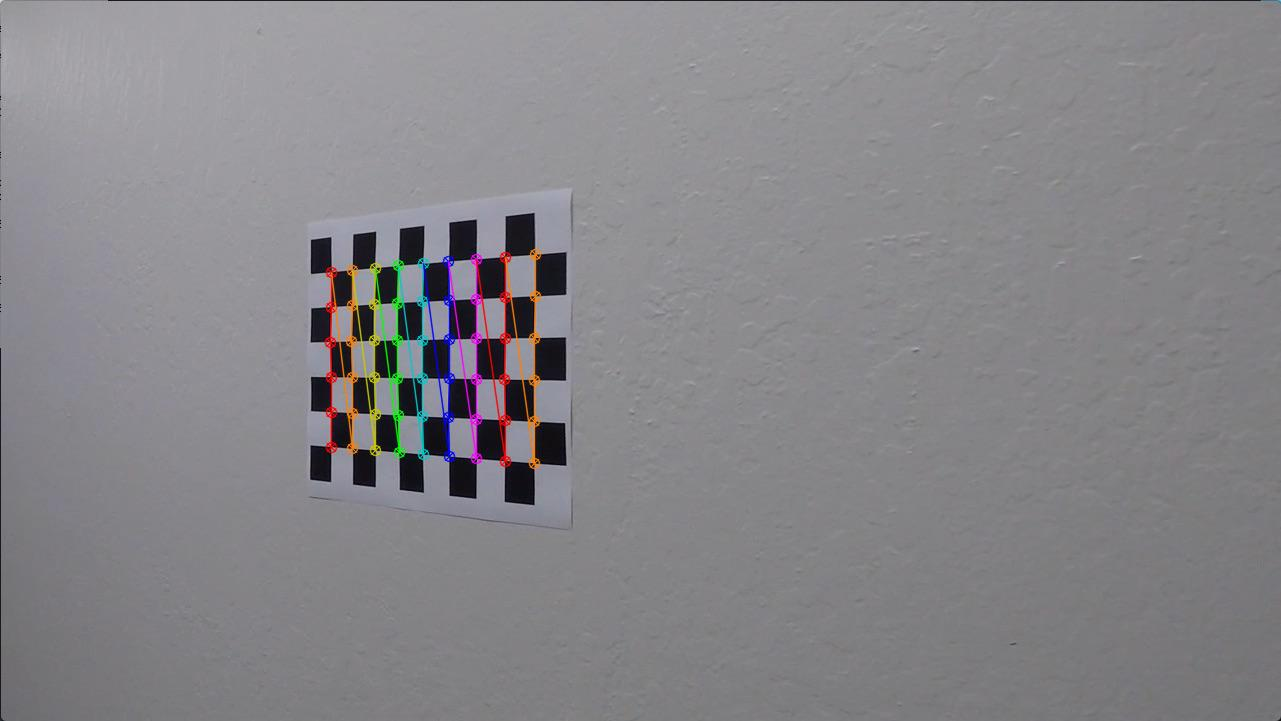

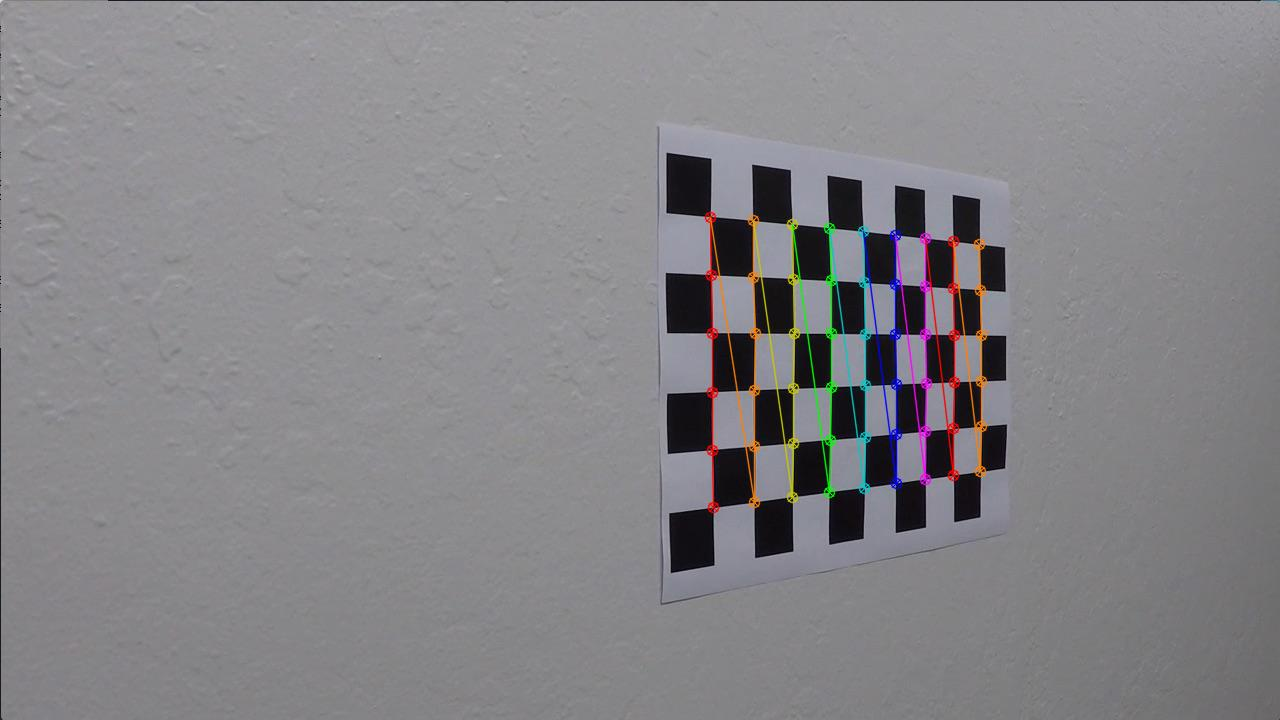

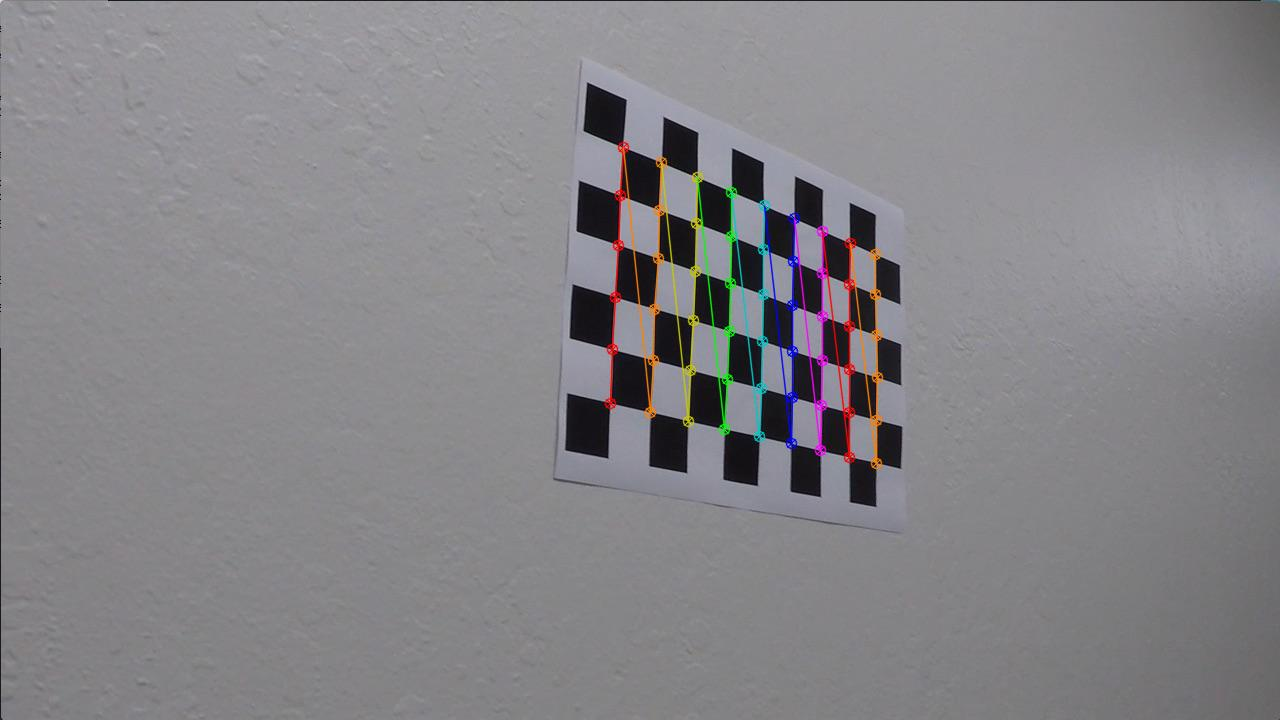

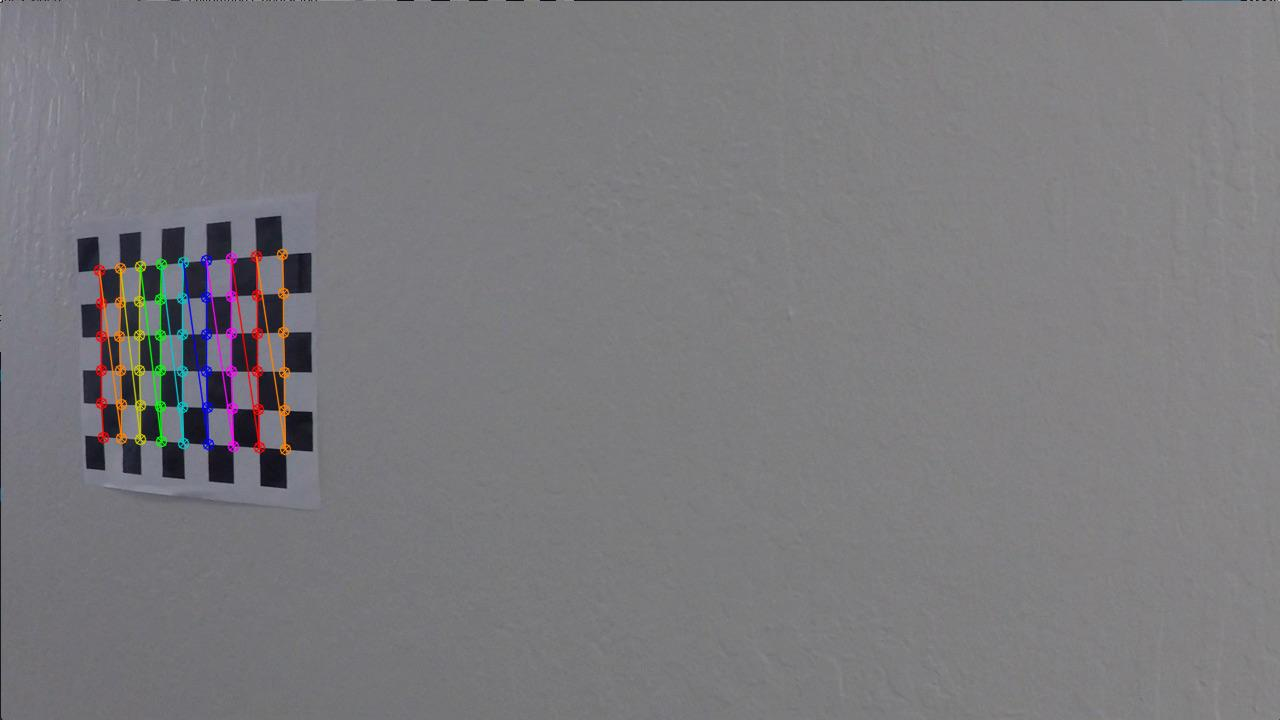

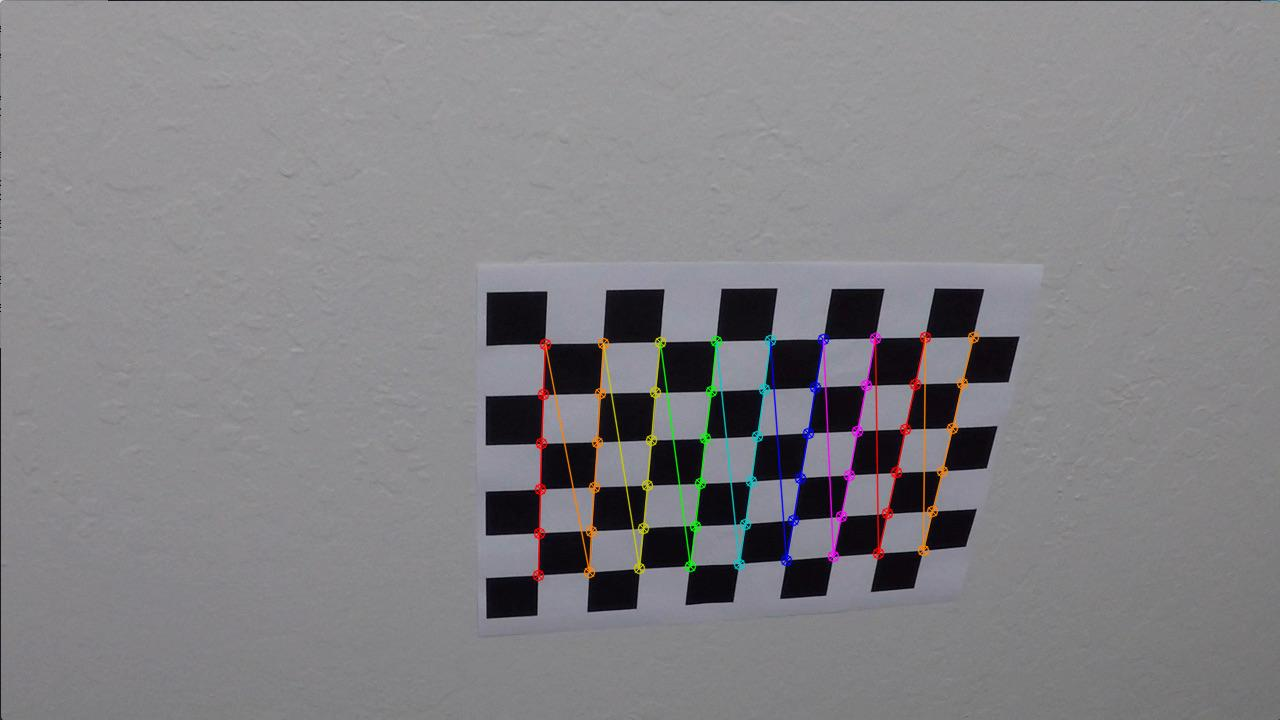

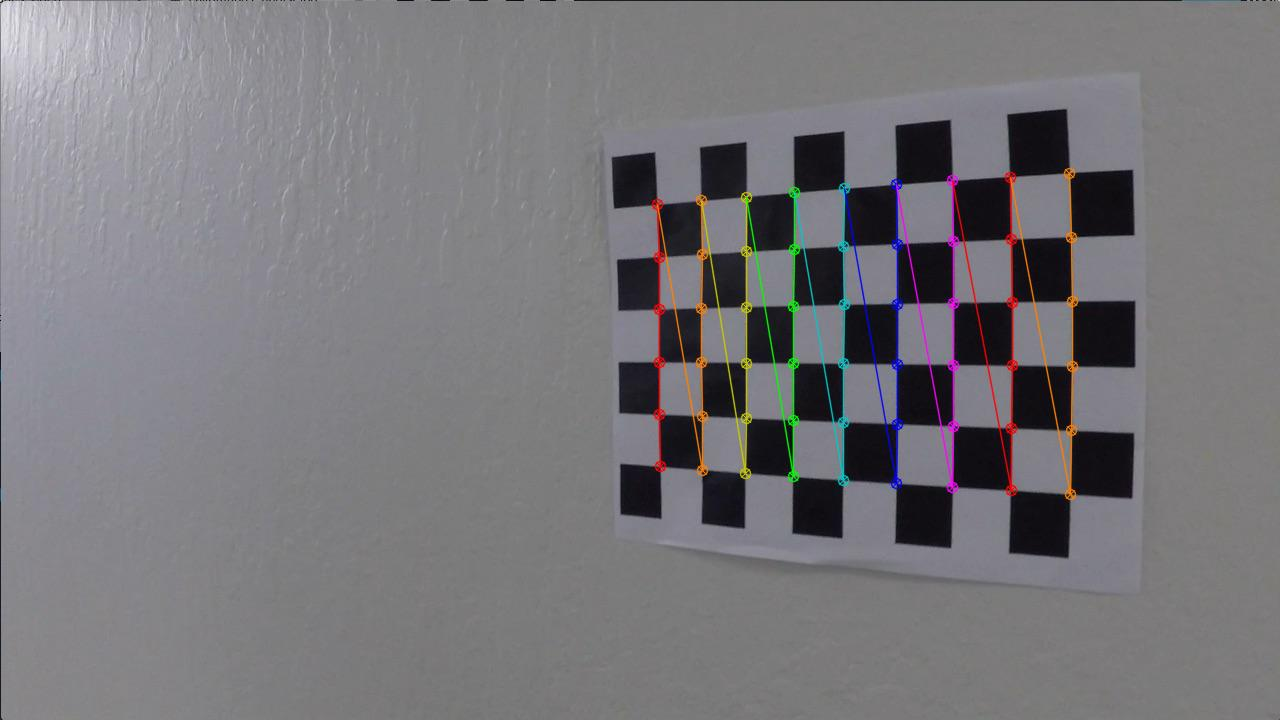

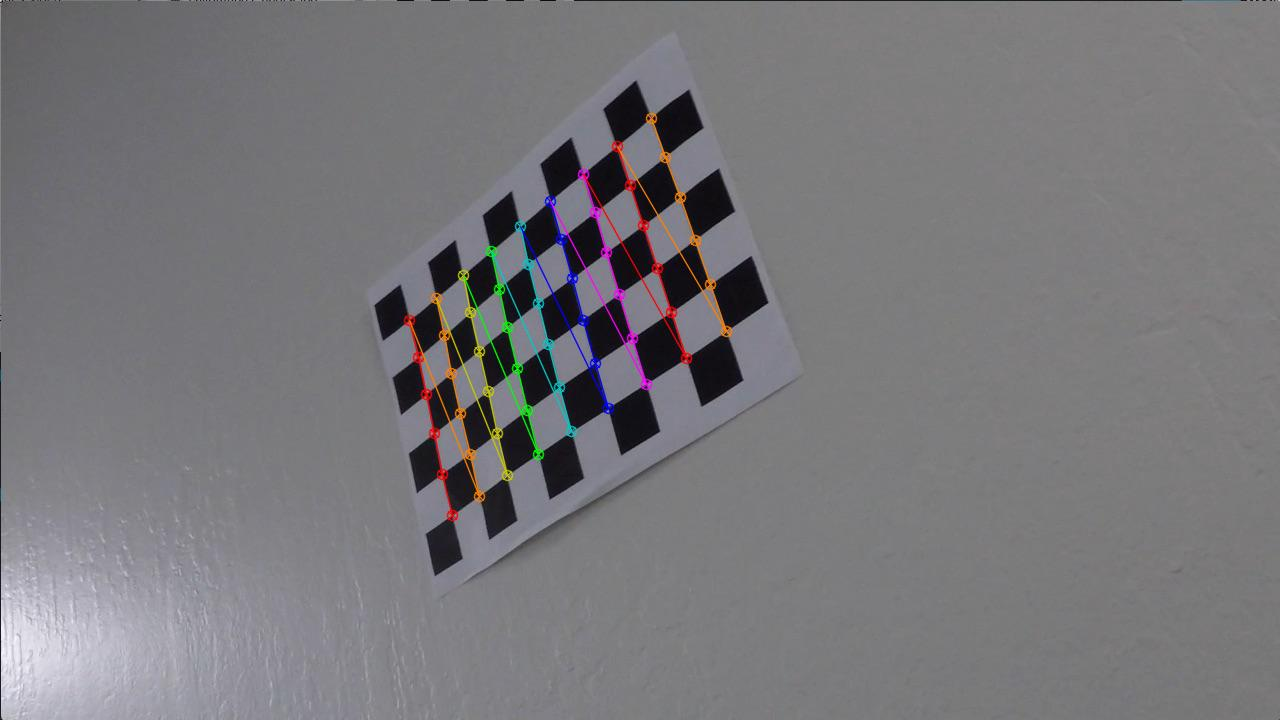

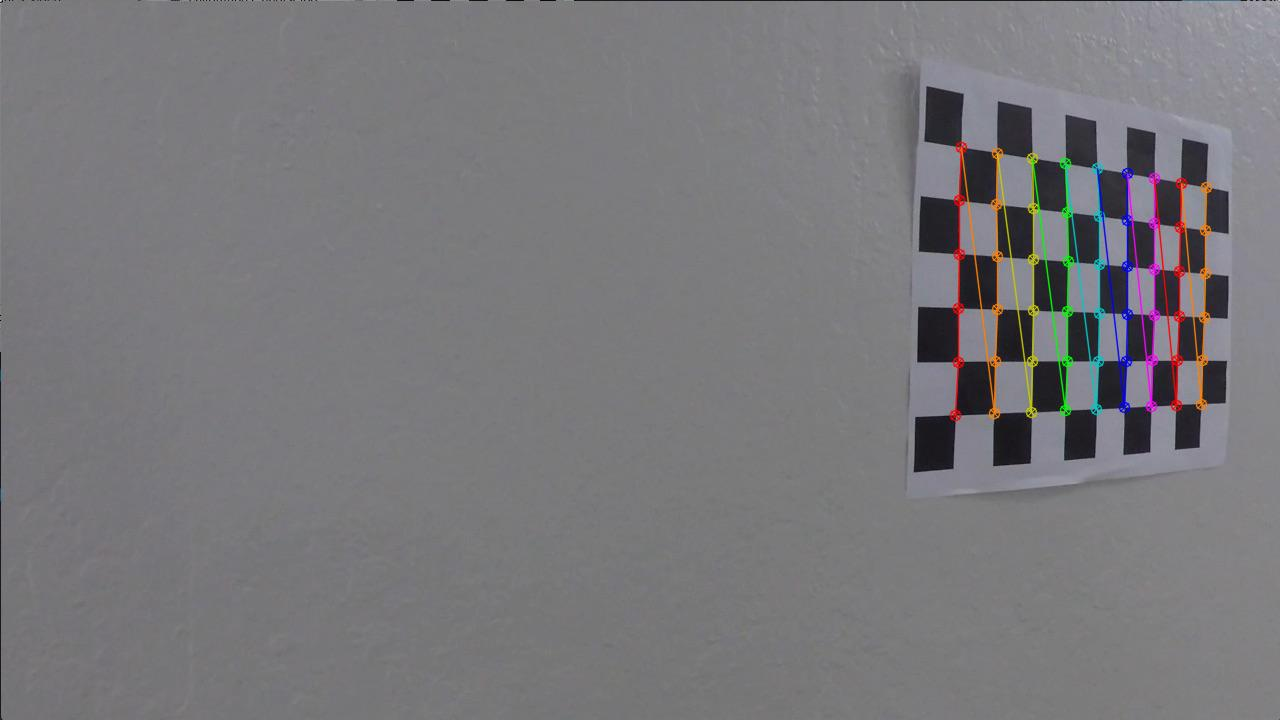

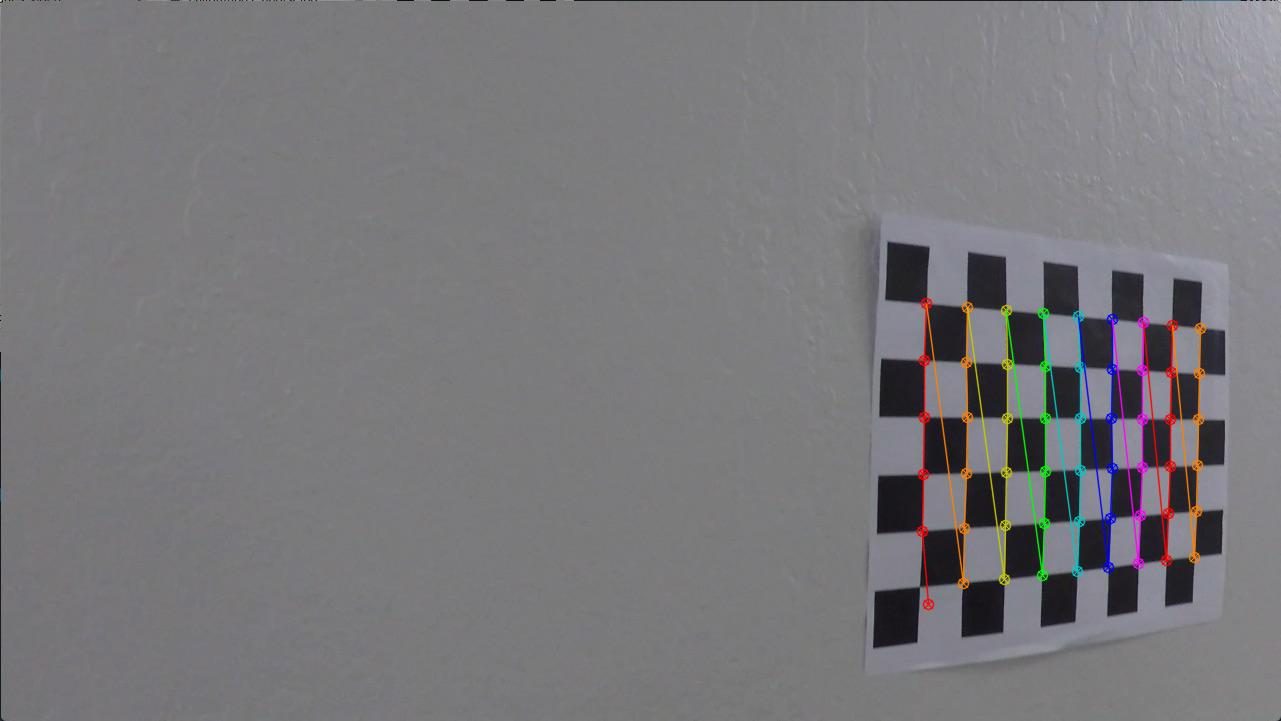

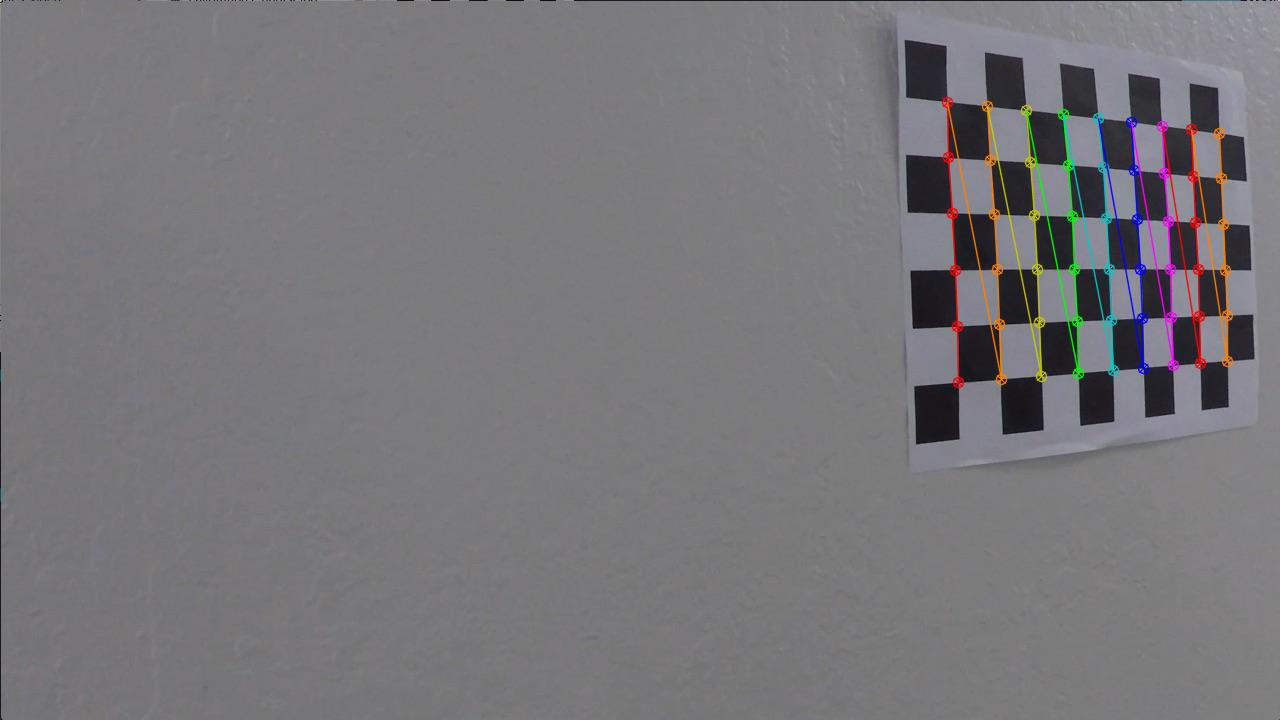

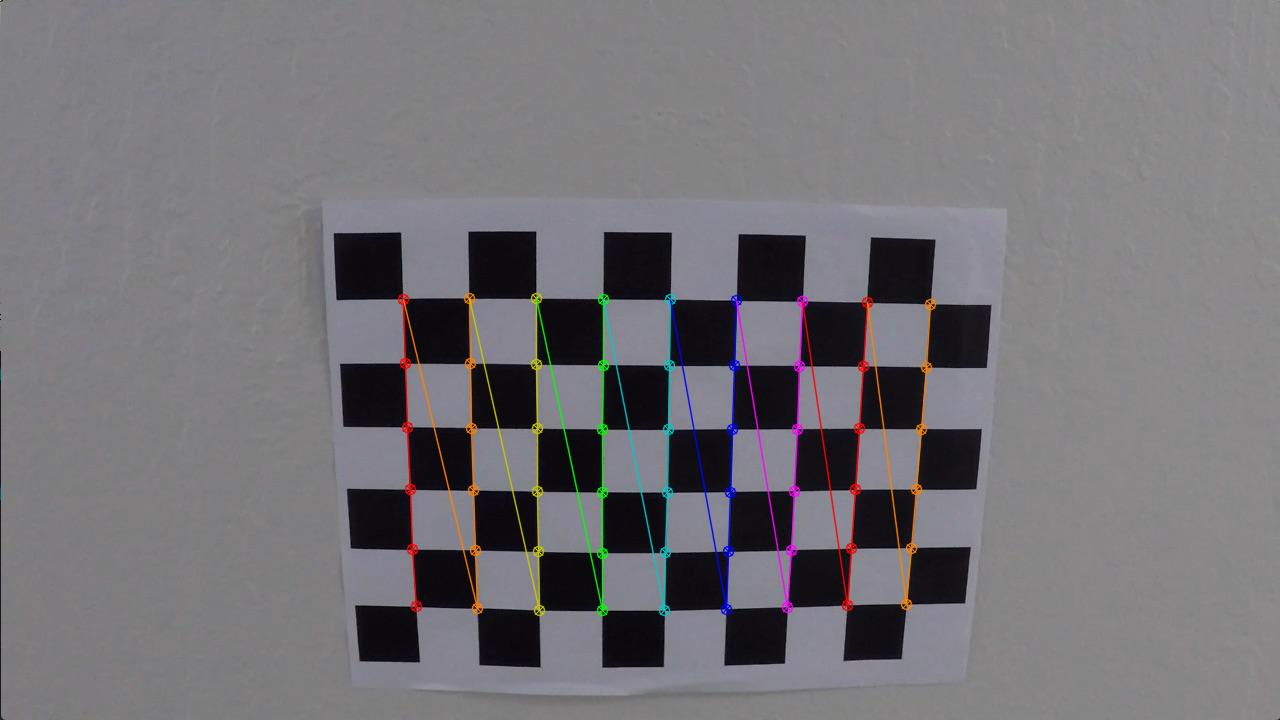

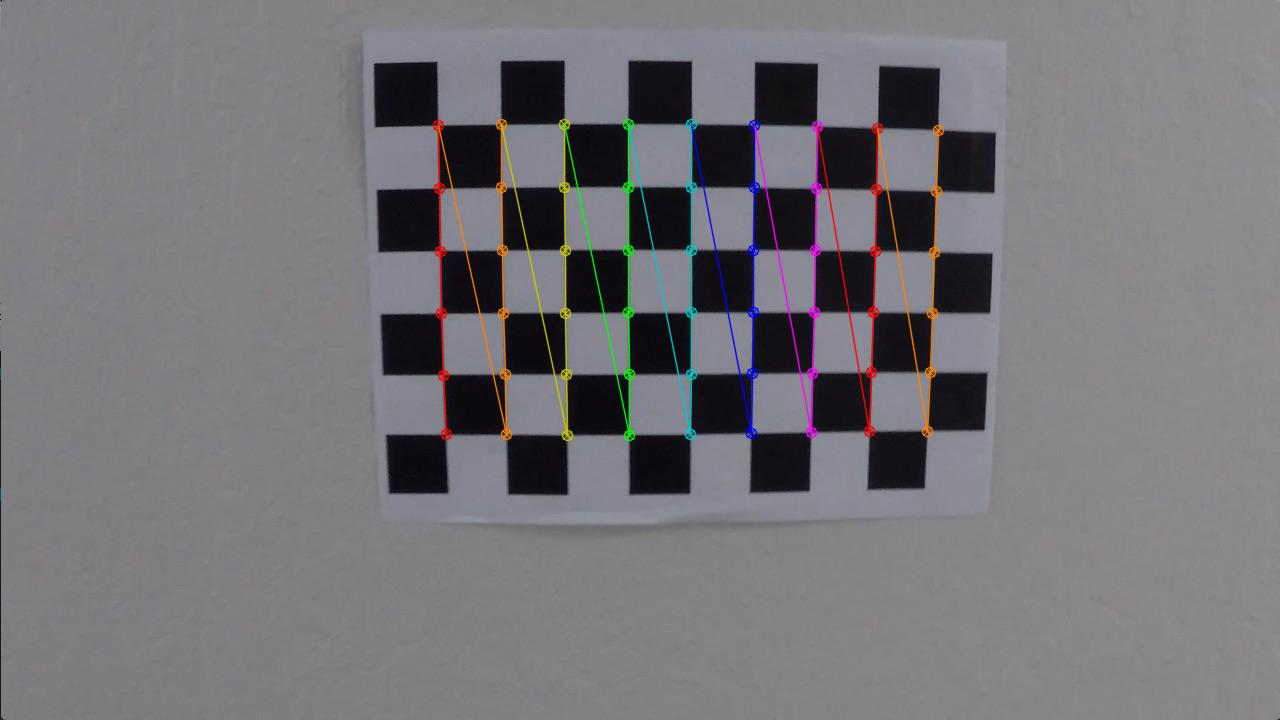

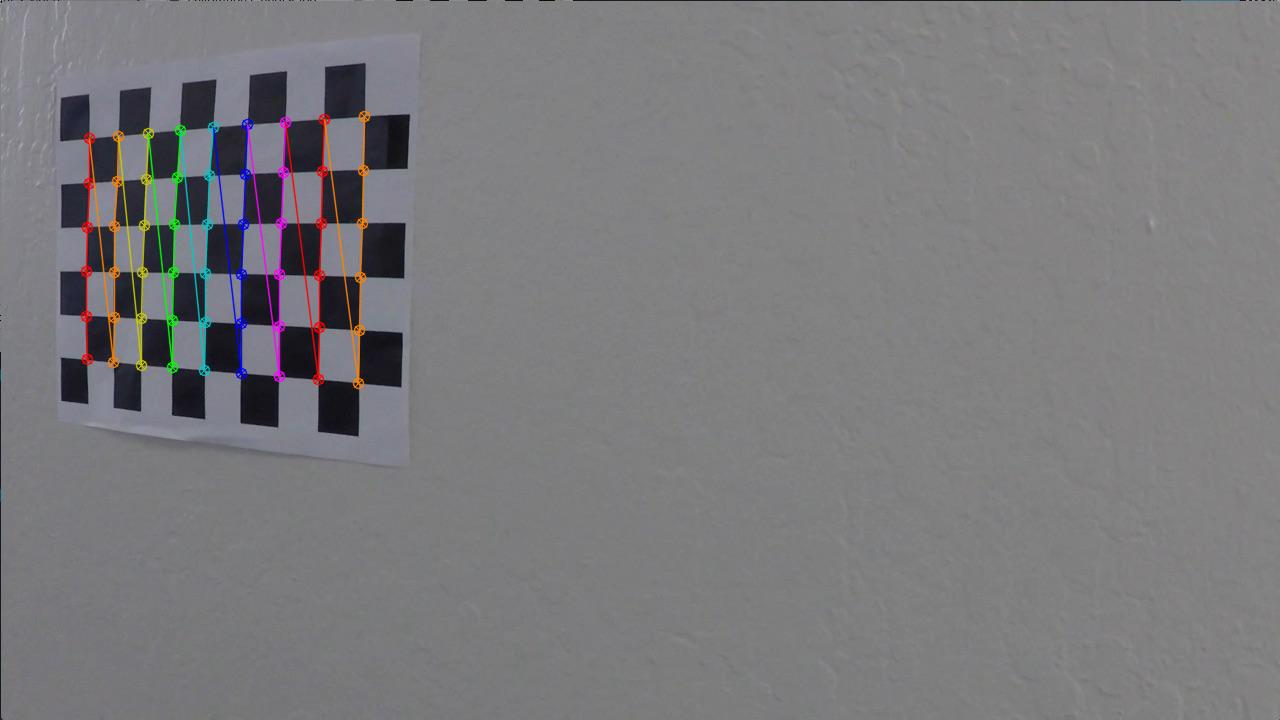

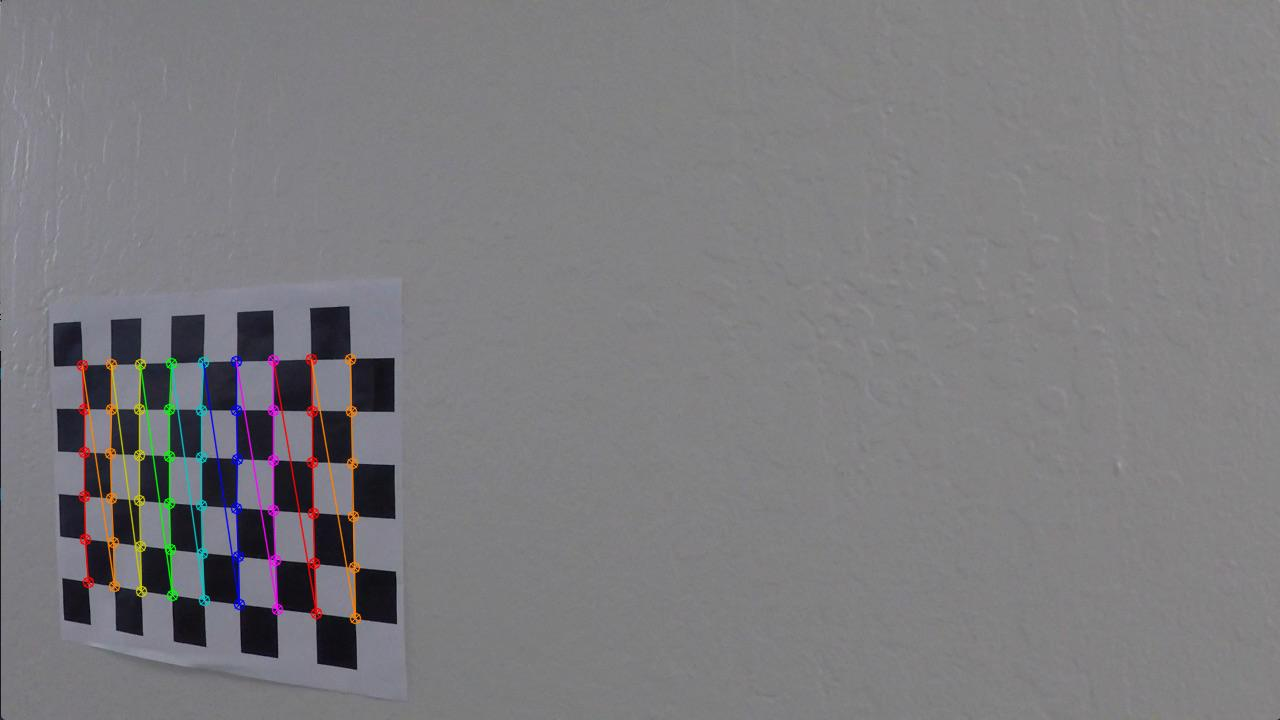

Camera matrix :
[[1.15645760e+03 0.00000000e+00 6.71319662e+02]
 [0.00000000e+00 1.15126726e+03 3.89216724e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
Distortion matrix:
[[-2.46670489e-01 -2.54444802e-02 -6.70224094e-04  1.34034383e-04
   1.06713670e-02]]


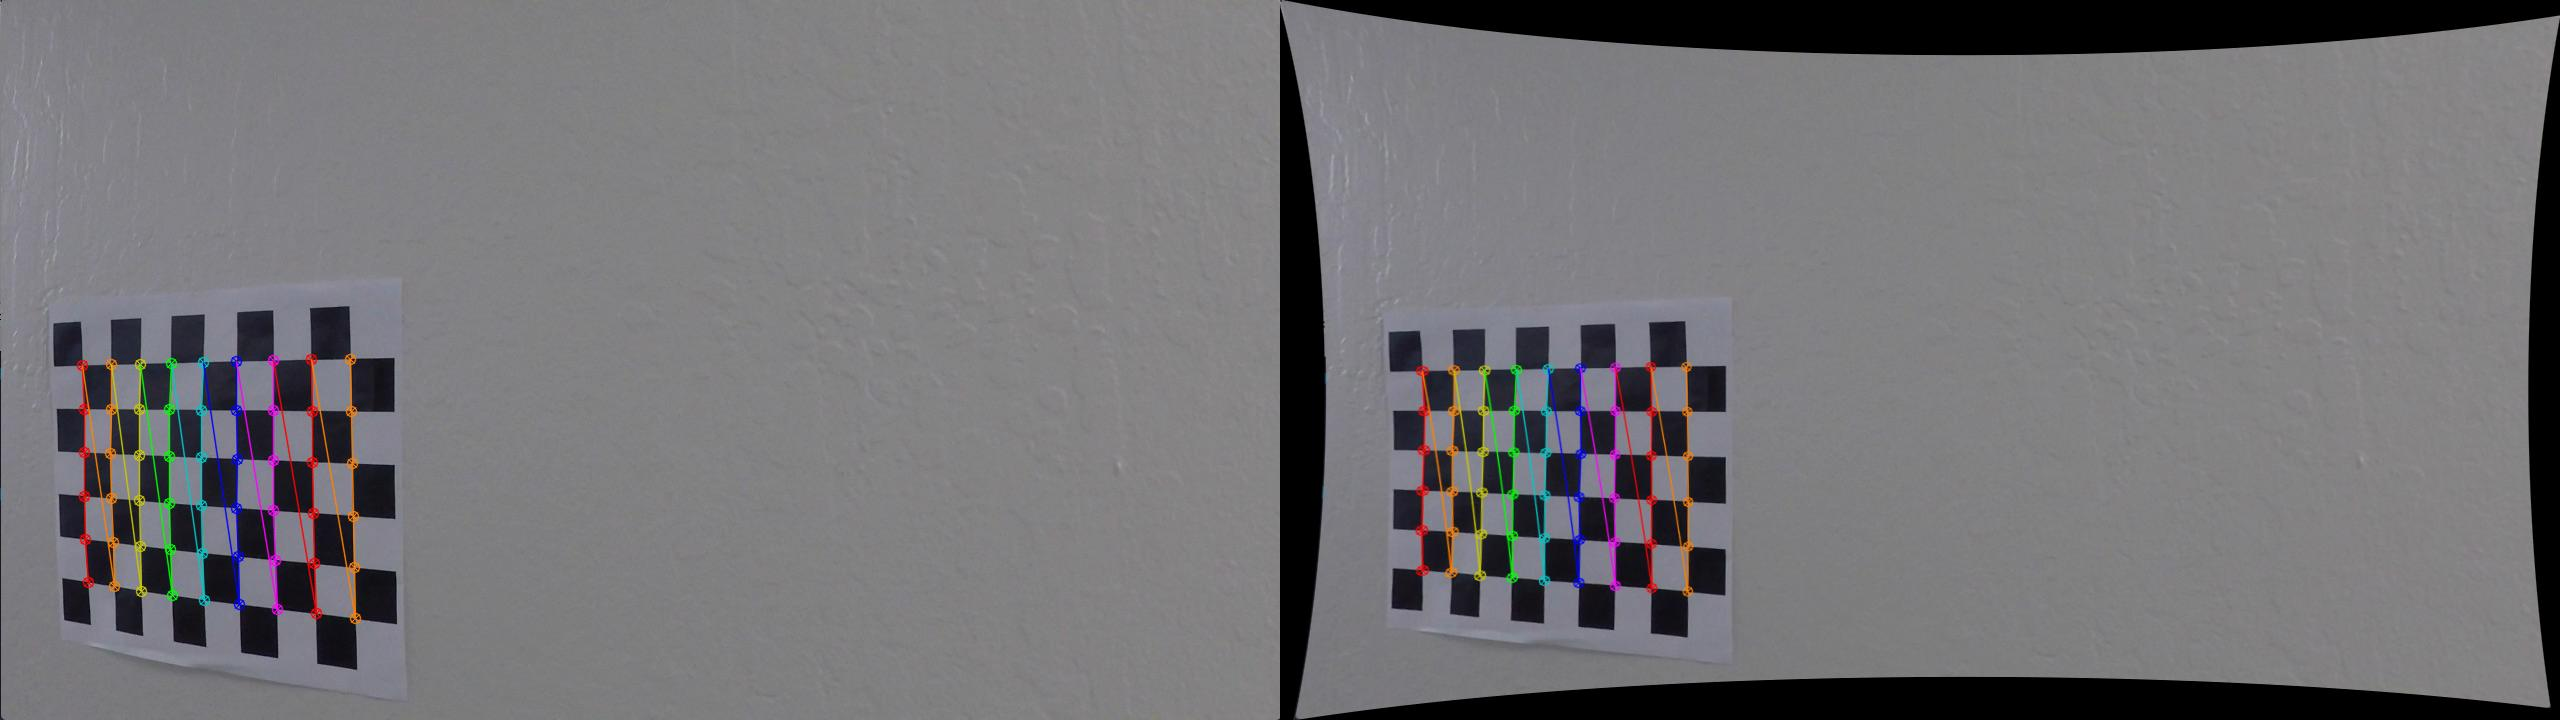

In [ ]:
#출처: https://learnopencv.com/camera-calibration-using-opencv/

import os
import glob
import numpy as np
import cv2
from google.colab.patches import cv2_imshow


# Defining the dimensions of checkerboard
CHECKERBOARD = (6,9)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)

# Creating vector to store vectors of 3D points for each checkerboard image
objpoints = []
# Creating vector to store vectors of 2D points for each checkerboard image
imgpoints = []


# Defining the world coordinates for 3D points
objp = np.zeros((1, CHECKERBOARD[0] * CHECKERBOARD[1], 3), np.float32)
objp[0,:,:2] = np.mgrid[0:CHECKERBOARD[0], 0:CHECKERBOARD[1]].T.reshape(-1, 2)
prev_img_shape = None

# Extracting path of individual image stored in a given directory
images = glob.glob('/content/drive/MyDrive/Colab Notebooks/photos/*.jpg')
for fname in images:
    img = cv2.imread(fname)
    gray = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
    # Find the chess board corners
    # If desired number of corners are found in the image then ret = true
    ret, corners = cv2.findChessboardCorners(gray, CHECKERBOARD, cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_FAST_CHECK + cv2.CALIB_CB_NORMALIZE_IMAGE)

    """
    If desired number of corner are detected,
    we refine the pixel coordinates and display
    them on the images of checker board
    """
    if ret == True:
        objpoints.append(objp)
        # refining pixel coordinates for given 2d points.
        corners2 = cv2.cornerSubPix(gray, corners, (11,11),(-1,-1), criteria)

        imgpoints.append(corners2)

        # Draw and display the corners
        img = cv2.drawChessboardCorners(img, CHECKERBOARD, corners2, ret)
        cv2_imshow(img)


h,w = img.shape[:2]

"""
Performing camera calibration by
passing the value of known 3D points (objpoints)
and corresponding pixel coordinates of the
detected corners (imgpoints)
"""
ret, mtx, dist, rvecs, tvecs = cv2.calibrateCamera(objpoints, imgpoints, gray.shape[::-1], None, None)

print("Camera matrix :")
print(mtx)
print("Distortion matrix:")
print(dist)

#Refining the camera matrix using parameters obtained by calibration
newcameramtx, roi = cv2.getOptimalNewCameraMatrix(mtx, dist, (w,h), 1, (w,h))

#Method 1: undistort() to undistort the image
dst = cv2.undistort(img, mtx, dist, None, newcameramtx)

# #Method 2: remap() to undistort the image
# mapx,mapy=cv2.initUndistortRectifyMap(mtx,dist,None,newcameramtx,(w,h),5)
# dst = cv2.remap(img,mapx,mapy,cv2.INTER_LINEAR)

#Displaying the undistorted image
checkerboard_frame = cv2.hconcat([img,dst])
cv2_imshow(checkerboard_frame)
